In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import time
from Functions.param_assoc import param_assoc
from Functions.kalman_filter import *

np.random.seed(100)

The below code defines all the functions used in the rest of the sections.

In [2]:
### Functions

# Function to calculate the CDF of the error
def cal_cdf(err, x):
    CDF = np.zeros(len(x))
    for iter in range(0, len(x)):
        CDF[iter] = np.sum(err <= x[iter])/len(err)
    return CDF


# Function to find LoS path using the estimated AoA and ToF
def find_los(t_est, theta_est, alpha_est, Doppler_est, aoa_ue):
    alpha_max = np.max(np.abs(alpha_est))
    
    while(len(t_est) > 0): # Continue until there is a path left to process
        l_ue = np.argmin(t_est) # Find the path index with the minimum transmit delay
        if (np.abs(theta_est[l_ue] - aoa_ue) > 7.5) or (np.abs(alpha_est[l_ue]) < 0.5*alpha_max): # Ignore the path if it is not coming from the UE or if it is too weak. LoS from the UE should be one of the strongest paths if not the strongest.
            t_est = np.delete(t_est, l_ue)
            theta_est = np.delete(theta_est, l_ue)
            alpha_est = np.delete(alpha_est, l_ue)
            Doppler_est = np.delete(Doppler_est, l_ue)
        else:
            break

    return t_est, theta_est, alpha_est, Doppler_est, l_ue


### Function to estimate the position of the object of interest from the estimated range, angle of the reflected path and distance of the UE from the gNB
def est_pos(d, l_hat, theta_hat):
    x1 = (d + l_hat)*np.sin(theta_hat)
    y1 = (d + l_hat)*np.cos(theta_hat)
    m = (y1 - d)/x1

    x_mid = x1/2
    y_mid = (y1 + d)/2

    x_s_hat = (x_mid/m + y_mid)/(1/m + 1/np.tan(theta_hat))
    y_s_hat = x_s_hat/np.tan(theta_hat)

    return x_s_hat, y_s_hat


# Function to estimate the full channel estimates from combed channel estimates using interpolation (Support only for K_TC = 2 for now)
def interpolate_channel_estimates(H_combed, nPRB, N_ifft, K_TC):
    H_combed = np.concatenate([H_combed[N_ifft-6*nPRB:N_ifft], H_combed[0:6*nPRB]])
    K_srs = int(np.ceil(12*nPRB / K_TC))
    H = np.zeros([12*nPRB], dtype=np.complex128)
    n = 0

    if K_TC == 2:
        filt8_start = np.array([12288, 8192, 4096, 0, 0, 0, 0, 0])/16384
        filt8_end = np.array([4096, 8192, 12288, 16384])/16384
        filt8_middle2 = np.array([4096, 8192, 8192, 8192, 4096, 0, 0, 0])/16384
        filt8_middle4 = np.array([0, 0, 4096, 8192, 8192, 8192, 4096, 0])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt8_start)] = H[n:n+len(filt8_start)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt8_start
            elif k == K_srs-1:
                H[n:n+len(filt8_end)] = H[n:n+len(filt8_end)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt8_end
            elif np.mod(k, 2) == 1:
                H[n:n+len(filt8_middle2)] = H[n:n+len(filt8_middle2)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt8_middle2
            elif np.mod(k, 2) == 0:
                H[n:n+len(filt8_middle4)] = H[n:n+len(filt8_middle4)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt8_middle4
                n = k*K_TC

    elif K_TC == 4:
        filt16_start = np.array([12288, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_end = np.array([4096, 8192, 8192, 8192, 12288, 16384, 16384, 16384, 0, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_middle = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt16_start)] = H[n:n+len(filt16_start)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_start
            elif k == K_srs-1:
                if n+len(filt16_end) > len(H):
                    H[n:len(H)] = H[n:len(H)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_end[0:len(H)-n]
                else:
                    H[n:n+len(filt16_end)] = H[n:n+len(filt16_end)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_end
            else:
                if n+len(filt16_middle) > len(H):
                    H[n:len(H)] = H[n:len(H)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_middle[0:len(H)-n]
                else:
                    H[n:n+len(filt16_middle)] = H[n:n+len(filt16_middle)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_middle
                n = k*K_TC

    elif K_TC == 8:
        filt16_start = np.array([12288, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_end = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 12288, 16384, 16384, 16384, 16384, 16384, 16384, 16384])/16384
        filt16_middle = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt16_start)] = H[n:n+len(filt16_start)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_start
            elif k == K_srs-1:
                if n+len(filt16_end) > len(H):
                    H[n:len(H)] = H[n:len(H)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_end[0:len(H)-n]
                else:
                    H[n:n+len(filt16_end)] = H[n:n+len(filt16_end)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_end
            else:
                if n+len(filt16_middle) > len(H):
                    H[n:len(H)] = H[n:len(H)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_middle[0:len(H)-n]
                else:
                    H[n:n+len(filt16_middle)] = H[n:n+len(filt16_middle)] + np.sum(H_combed[k*K_TC:(k+1)*K_TC])*filt16_middle
                n = k*K_TC
            

    H = np.concatenate([H[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), H[0:6*nPRB]])
    
    return H

The below code defines all the channel parameters.

In [3]:
### Signal and system parameters

D = np.array([20, 20, 20]) # distance of the UE from the gNB (in m)
AoA_UE = np.array([0, 0, 0, 0, 0, 0, 0]) # AoA of the UE (in radians)
c = 299792458
f_c = 3.6192e9
bandwidth = 20e6
scs = 30e3
K_TC = 2 # This is the SRS transmission comb
K_TC_dmrs = 2

if bandwidth == 20e6:
    f_s = 30.72e6
    N_ifft = 1024
    nPRB = 51
    N_cp = 72
    occ_bandwidth = 12*nPRB*scs
    nPRB_dmrs = 25
    print("Bandwidth is 20 MHz")

elif bandwidth == 40e6:
    f_s = 61.44e6
    N_ifft = 2048
    nPRB = 106
    N_cp = 144
    occ_bandwidth = 12*nPRB*scs
    nPRB_dmrs = 50
    print("Bandwidth is 40 MHz")

elif bandwidth == 80e6:
    f_s = 122.88e6
    N_ifft = 4096
    nPRB = 217
    N_cp = 288
    occ_bandwidth = 12*nPRB*scs
    print("Bandwidth is 80 MHz")

osf = 8
N_ant = 4
d_ant = 1/2*np.arange(0, N_ant, 1) # inter-element distance (in terms of wavelength)
P_t = 0.1 # Watt
K = 1.380649e-23
T = 298
noise_var = K*bandwidth*T
srs_period = 20e-3 # SRS transmission period in seconds
dmrs_period = 2.5e-3 # DMRS transmission period in seconds

trajectories = np.array(['Trajectory_1', 'Trajectory_2'])
iter_traj = 0 # This variable is used to select the trajectory for simulation. It can take values 0, 1, or 2.

### Channel parameters
chan_params = np.load('/home/bkumar2/Documents/Research/ISAC/Python_Scripts_CellSense2.0/Simulation/Datasets/Outdoor_scenario/' + trajectories[iter_traj] + '/ISAC_ray_tracing_chan.npy')
positions = np.load('/home/bkumar2/Documents/Research/ISAC/Python_Scripts_CellSense2.0/Simulation/Datasets/Outdoor_scenario/' + trajectories[iter_traj] + '/ISAC_locations.npy')
obj_params = np.load('/home/bkumar2/Documents/Research/ISAC/Python_Scripts_CellSense2.0/Simulation/Datasets/Outdoor_scenario/' + trajectories[iter_traj] + '/obj_params.npy')

visibility = obj_params[:, 3] # This array indicates the ground truth of object visibility to the BS.

K = 500
tau = chan_params[:, 2, :] # Transmit delay in s 
theta = chan_params[:, 0, :] # AoA in radians
Doppler = chan_params[:, 1, :] # Doppler in Hz 
pathgain = chan_params[:, 3, :] # Pathgain in absolute value

L = np.shape(tau)[1]

for k in range(0, K):
    order = np.argsort(pathgain[k, :])[::-1]
    tau[k, :] = tau[k, order]
    theta[k, :] = theta[k, order]
    Doppler[k, :] = Doppler[k, order]
    pathgain[k, :] = pathgain[k, order]

# Repeat the same values K times for averaging (Monte carlo simulation)
# tau = np.tile(np.reshape(tau, [1, len(tau)]), [K, 1])
# theta = np.tile(np.reshape(theta, [1, len(theta)]), [K, 1])
theta = theta + np.pi
theta = np.pi/2 - theta
theta = (theta + np.pi) % (2 * np.pi) - np.pi
obj_params[:, 0] = np.pi/180*obj_params[:, 0]  # This variable stores the AoA of the object of interest
obj_params[:, 0] = obj_params[:, 0] + np.pi
obj_params[:, 0] = np.pi/2 - obj_params[:, 0]
obj_params[:, 0] = (obj_params[:, 0] + np.pi) % (2 * np.pi) - np.pi
obj_params[:, 0] = 180/np.pi*obj_params[:, 0]
# Doppler = np.tile(np.reshape(Doppler, [1, len(Doppler)]), [K, 1])
pathgain = P_t*pathgain/noise_var

L = 25
tau = tau[:, 0:L]
theta = theta[:, 0:L]
Doppler = Doppler[:, 0:L]
pathgain = pathgain[:, 0:L]

Bandwidth is 20 MHz


The below code is used for running comparison tests between SRS and DMRS for a 2-tap channel (LoS and a Object path).

This comparison is only for AoA and ToF, so we are only using a single OFDM symbol for estimation.

In [4]:
np.random.seed(10)

K = 10
# nPRB_dmrs = 25

tau_space = np.arange(4, 100, 2)
theta_space = np.arange(-75, 75, 3)*np.pi/180

rmse_tau = np.zeros([len(theta_space), len(tau_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space)])
detection = np.zeros([len(theta_space), len(tau_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):

        print("Starting {}th AoA and {}th ToA \n".format(iter3, iter2))

        err_Doppler_1 = np.zeros([K])
        err_theta_1 = np.zeros([K])
        err_tau_1 = np.zeros([K])
        detect_1 = np.zeros([K])
        est_Doppler_1 = np.zeros([K])
        est_theta_1 = np.zeros([K])
        est_tau_1 = np.zeros([K])

        obj_theta = theta_space[iter3]*np.ones(K)
        obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
        obj_Doppler = np.zeros(K)
        obj_pathgain = 10000*np.ones(K)
        obj_phase = 2*np.pi*np.random.rand(K)

        gen_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
        rcvd_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

        for k in range(0, K):
            Xn = np.zeros([12*nPRB], dtype=np.complex128)

            m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
            Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)

            # m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
            # Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
            
            Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
            Xn = np.reshape(Xn, [N_ifft, 1])

            X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
            X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
            # X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
            X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

            t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
            n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
            n = np.reshape(n, [N_ifft, 1])
            n = np.tile(n, [1, N_ifft])

            # This loop just generates the OFDM samples in time domain
            temp_xn = np.tile(Xn, [1, N_ifft])
            phase = -f_c*tau[0, :]

            for l in range(0, 1):
                if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                    gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase[k]) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau[k], [1, N_ifft]), [N_ifft, 1])), axis=0)
            gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

            # Add the AWGN noise to the generated samples
            rcvd_signal[k, :, :] = gen_signal[k, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


        ### Channel estimation

        # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
        rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=2)

        # Estimate the channel using X_pilot as pilot symbols
        H_combed = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) 

        for i in range(0, N_ifft):
            if X_pilot[i] == 0:
                H_combed[:, :, i] = np.zeros([K, N_ant])
            else:
                H_combed[:, :, i] = rcvd_sig_freq[:, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_ant]))
    
        H = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)
        for k in range(0, K):
            for n_ant in range(0, N_ant):
                H[k, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_ant, :], nPRB, N_ifft, K_TC_dmrs)


        Xn = np.zeros([12*nPRB], dtype=np.complex128)
        # m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn shouold occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
        # Xn[np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

        m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
        Xn[np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

        Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
        Xn = np.reshape(Xn, [N_ifft, 1])

        # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
        complex_rxsym0 = H[:, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
        complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
        complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
        complex_rxsym1 = H[:, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
        complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
        complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
        complex_rxsym2 = H[:, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
        complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
        complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
        complex_rxsym3 = H[:, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
        complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
        complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)


        # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
        Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
        time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

        T_obs = 1

        for iter0 in range(0, K):
            print("---------------------Start of {}th symbol------------------------".format(iter0))
            
            est_mean_time0 = complex_time0[iter0, :]
            est_mean_time1 = complex_time1[iter0, :]
            est_mean_time2 = complex_time2[iter0, :]
            est_mean_time3 = complex_time3[iter0, :]

            mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

            resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
            L = 3 # No. of paths estimated
            parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

            # Search space for the parameters
            f_search = 0*np.arange(-24, 24, 1)
            t_search = np.arange(-50, 100, 1)
            theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
            
            for iter in range(0, resolve):

                beam_strength = np.zeros([len(theta_search), L])
                caf_freq = np.zeros([len(f_search), L])
                caf_time = np.zeros([len(t_search), L])
                
                for l in range(0, L):

                    # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                    if iter > 0:
                        generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, T_obs*osf*N_ifft])

                        generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1)

                        generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

                        generated_sig = parameters[3, l]*generated_sig
                        mean_chan_subcarrier = generated_sig + residual_sig

                    if iter > 1:
                        theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                        
                    est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

                    # mean_chan = np.average(est_mean_rxsym, axis=1)

                    # START - Code for beam sweeping here and finding the strongest direction.

                    for i in range(0, len(theta_search)):
                        beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)

                        # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                        
                    max_idx = np.argmax(beam_strength[:, l])
                    max_theta = theta_search[max_idx] 

                    parameters[0, l] = max_theta
                    # END - Code for beam sweeping here and finding the strongest direction.

                    # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

                    n = np.arange(0, osf*N_ifft, 1)

                    combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, T_obs*osf*N_ifft])*mean_chan_subcarrier, axis=0)

                    max_caf = 0
                    for t in range(0, len(t_search)):
                        caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) 
                        
                        if caf_time[t,l] > max_caf:
                            t_best = t
                            max_caf = caf_time[t,l]
                        
                    # max_caf = 0
                    # shifted_combined_chan = np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[0:osf*N_ifft]
                    # for f in range(0, len(f_search)):
                    #     caf_freq[f, l] = np.abs(np.sum(shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))))
                    #     if caf_freq[f,l] > max_caf:
                    #         f_best = f
                    #         max_caf = caf_freq[f,l]
                    f_best = 0

                    # idx = np.argmax(caf[:, :, l])
                    # f_best, t_best = np.unravel_index(idx, caf[:, :, l].shape)

                    parameters[1, l] = f_search[f_best]
                    parameters[2, l] = t_search[t_best]

                    # END - Code for estimating the transmit delay and Doppler using CAF

                    # START - Code that is used to regenerate the signal using the estimated parameters

                    generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, T_obs])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, T_obs*osf*N_ifft])

                    generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1)

                    generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])
                                                
                    alpha = np.average(mean_chan_subcarrier/generated_sig)

                    parameters[3, l] = alpha

                    generated_sig = alpha*generated_sig

                    residual_sig = mean_chan_subcarrier - generated_sig

                    mean_chan_subcarrier = residual_sig

                    # END - Code that is used to regenerate the signal using the estimated parameters

            t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
            theta_est = np.real(parameters[0, :])*180/np.pi
            alpha_est = np.abs(parameters[3, :])
            Doppler_est = np.real(parameters[1, :])
            t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

            err_max = 100
            for l in range(0, len(t_est)):
                if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                    
                    err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                    l_obj = l

            print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
            print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
            print("Estimated ToA for shortlisted paths: ", t_est)

            if (err_max < 100) and len(t_est) > 0:
                print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                print(l_ue)
                print(l_obj)

                err_theta_1[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                err_tau_1[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                err_Doppler_1[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                detect_1[iter0] = 1
                
                est_Doppler_1[iter0] = Doppler_est[l_obj]
                est_theta_1[iter0] = theta_est[l_obj]
                est_tau_1[iter0] = t_est[l_obj] - t_est[l_ue]

        idx = np.where(detect_1 == 1)
        rmse_tau[iter3, iter2] = np.sqrt(np.sum(err_tau_1[idx[0]]**2)/len(idx[0]))
        rmse_theta[iter3, iter2] = np.sqrt(np.sum(err_theta_1[idx[0]]**2)/len(idx[0]))
        detection[iter3, iter2] = len(idx[0])/K*100

Starting 0th AoA and 0th ToA 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353  -73.90563307  -4.57773986]
Estimated ToA for all paths:  [65.10416667 69.17317708 40.69010417]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 0.0 Doppler of the object
0
1
---------------------Start of 1th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353  -75.62450646   4.01662706]
Estimated ToA for all paths:  [65.10416667 69.17317708 89.51822917]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 89.51822917]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 0.0 Doppler of the object
0
1
---------------------Start of 2th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01 -5.67035296e-01]
Estimated ToA for all paths:  [65.10416667

The below code is used for running comparison tests between SRS and DMRS by generating results for SRS-only and DMRS-only cases for a 2-tap channel (LoS and a Object path).

This comparison is for AoA, ToF and Doppler, so we are using 4 OFDM symbols for estimation. 

Assumption -> All OFDM symbols have the same absolute time offset. However, we are not going to perform parameter estimation using all 4 symbols in tandem. This assumption is only made to not let the time offset correction to affect the comparison between SRS, DMRS and SRS+DMRS.

Process for parameter estimation -
1. Perform parameter estimation for one OFDM symbol and extract the AoA and ToF for that instance
2. Using those AoA and ToF estimates perform another stage of iterative parameter estimation using 4 OFDM symbols and only for Doppler this time
3. The above two steps are for SRS only and DMRS only scenarios. When we are using DMRS+SRS, we perform one OFDM symbol estimation using SRS and Doppler estimation using DMRS

In [8]:
np.random.seed(10)

K = 1
N_SYM = 4
sym_delays = np.array([0, srs_period, 4*srs_period, 10*srs_period])
# nPRB_dmrs = 25

tau_space = np.arange(4, 100, 4)
theta_space = np.arange(-75, 75, 5)*np.pi/180
Doppler_space = np.array([15, 30])

rmse_tau = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_Doppler = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
detection = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):
        for iter4 in range(0, len(Doppler_space)):

            print("Starting {}th AoA, {}th ToA and {}th Doppler \n".format(iter3, iter2, iter4))

            err_Doppler = np.zeros([K])
            err_theta = np.zeros([K])
            err_tau = np.zeros([K])
            detect = np.zeros([K])
            est_Doppler = np.zeros([K])
            est_theta = np.zeros([K])
            est_tau = np.zeros([K])

            obj_theta = theta_space[iter3]*np.ones(K)
            obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
            obj_Doppler = Doppler_space[iter4]*np.ones(K)
            obj_pathgain = 10000*np.ones(K)

            gen_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    obj_tau_temp = obj_tau[k] - Doppler_space[iter4]*sym_delays[n_sym]/f_c
                    obj_phase = -f_c*obj_tau_temp

                    Xn = np.zeros([12*nPRB], dtype=np.complex128)

                    m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
                    Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)

                    # m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
                    # Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
                    
                    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                    Xn = np.reshape(Xn, [N_ifft, 1])

                    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                    X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
                    # X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
                    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                    n = np.reshape(n, [N_ifft, 1])
                    n = np.tile(n, [1, N_ifft])

                    # This loop just generates the OFDM samples in time domain
                    temp_xn = np.tile(Xn, [1, N_ifft])
                    phase = -f_c*tau[0, :]

                    for l in range(0, 1):
                        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                            gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                    gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    # Add the AWGN noise to the generated samples
                    rcvd_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


            ### Channel estimation

            # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
            rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=3)

            # Estimate the channel using X_pilot as pilot symbols
            H_combed = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)

            for i in range(0, N_ifft):
                if X_pilot[i] == 0:
                    H_combed[:, :, :, i] = np.zeros([K, N_SYM, N_ant])
                else:
                    H_combed[:, :, :, i] = rcvd_sig_freq[:, :, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_SYM, N_ant]))
        
            H = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)
            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    for n_ant in range(0, N_ant):
                        H[k, n_sym, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_sym, n_ant, :], nPRB, N_ifft, K_TC_dmrs)


            Xn = np.zeros([12*nPRB], dtype=np.complex128)
            # m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn shouold occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
            # Xn[np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
            Xn[np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
            Xn = np.reshape(Xn, [N_ifft, 1])

            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H[:, :, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym0[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=2)
            complex_rxsym1 = H[:, :, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym1[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=2)
            complex_rxsym2 = H[:, :, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym2[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=2)
            complex_rxsym3 = H[:, :, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym3[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=2)


            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
            time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

            for iter0 in range(0, K):
                print("---------------------Start of {}th symbol------------------------".format(iter0))
                
                est_mean_time0 = complex_time0[iter0, 0, :]
                est_mean_time1 = complex_time1[iter0, 0, :]
                est_mean_time2 = complex_time2[iter0, 0, :]
                est_mean_time3 = complex_time3[iter0, 0, :]

                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
                parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

                # Search space for the parameters
                f_search = 0*np.arange(-24, 24, 1)
                t_search = np.arange(-50, 100, 1)
                theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
                
                for iter in range(0, resolve):

                    beam_strength = np.zeros([len(theta_search), L])
                    caf_freq = np.zeros([len(f_search), L])
                    caf_time = np.zeros([len(t_search), L])
                    
                    for l in range(0, L):

                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, osf*N_ifft])

                            generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1)

                            generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig

                        if iter > 1:
                            theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                            
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

                        # mean_chan = np.average(est_mean_rxsym, axis=1)

                        # START - Code for beam sweeping here and finding the strongest direction.

                        for i in range(0, len(theta_search)):
                            beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)

                            # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                            
                        max_idx = np.argmax(beam_strength[:, l])
                        max_theta = theta_search[max_idx] 

                        parameters[0, l] = max_theta
                        # END - Code for beam sweeping here and finding the strongest direction.

                        # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

                        n = np.arange(0, osf*N_ifft, 1)

                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])*mean_chan_subcarrier, axis=0)

                        max_caf = 0
                        for t in range(0, len(t_search)):
                            caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) 
                            
                            if caf_time[t,l] > max_caf:
                                t_best = t
                                max_caf = caf_time[t,l]
                            
                        # max_caf = 0
                        # shifted_combined_chan = np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[0:osf*N_ifft]
                        # for f in range(0, len(f_search)):
                        #     caf_freq[f, l] = np.abs(np.sum(shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))))
                        #     if caf_freq[f,l] > max_caf:
                        #         f_best = f
                        #         max_caf = caf_freq[f,l]
                        f_best = 0

                        # idx = np.argmax(caf[:, :, l])
                        # f_best, t_best = np.unravel_index(idx, caf[:, :, l].shape)

                        parameters[1, l] = f_search[f_best]
                        parameters[2, l] = t_search[t_best]

                        # END - Code for estimating the transmit delay and Doppler using CAF

                        # START - Code that is used to regenerate the signal using the estimated parameters

                        generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])

                        generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1)

                        generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])
                                                    
                        alpha = np.average(mean_chan_subcarrier/generated_sig)

                        parameters[3, l] = alpha

                        generated_sig = alpha*generated_sig

                        residual_sig = mean_chan_subcarrier - generated_sig

                        mean_chan_subcarrier = residual_sig

                        # END - Code that is used to regenerate the signal using the estimated parameters

                est_mean_time0 = np.concatenate([complex_time0[iter0, 0, :], complex_time0[iter0, 1, :], complex_time0[iter0, 2, :], complex_time0[iter0, 3, :]])
                est_mean_time1 = np.concatenate([complex_time1[iter0, 0, :], complex_time1[iter0, 1, :], complex_time1[iter0, 2, :], complex_time1[iter0, 3, :]])
                est_mean_time2 = np.concatenate([complex_time2[iter0, 0, :], complex_time2[iter0, 1, :], complex_time2[iter0, 2, :], complex_time2[iter0, 3, :]])
                est_mean_time3 = np.concatenate([complex_time3[iter0, 0, :], complex_time3[iter0, 1, :], complex_time3[iter0, 2, :], complex_time3[iter0, 3, :]])
        
                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)
        
                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
        
                # Search space for the parameters
                f_search = np.arange(-25, 24, 1)
                
                for iter in range(0, resolve):
        
                    caf_freq = np.zeros([len(f_search), L])
                    
                    for l in range(0, L):
        
                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
        
                            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                            
                            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*4*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*10*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
        
                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig
                
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))
        
                        # START - Code for estimating the Doppler using CAF (Cross Ambiguity function)
        
                        n = np.arange(0, osf*N_ifft, 1)
        
                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])*mean_chan_subcarrier, axis=0)
                            
                        max_caf = 0
                        shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym), int(np.real(parameters[2, l])))*combined_chan[0:osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), int(np.real(parameters[2, l])))*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), int(np.real(parameters[2, l])))*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), int(np.real(parameters[2, l])))*combined_chan[3*osf*N_ifft:4*osf*N_ifft]])
                        for f in range(0, len(f_search)):
                            caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                        np.exp(-1j*2*np.pi*f_search[f]*srs_period)*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                        np.exp(-1j*2*np.pi*f_search[f]*4*srs_period)*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                        np.exp(-1j*2*np.pi*f_search[f]*10*srs_period)*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))])))
                            if caf_freq[f,l] > max_caf:
                                f_best = f
                                max_caf = caf_freq[f,l]
        
                        parameters[1, l] = f_search[f_best]
                        
                        # END - Code for estimating the Doppler using CAF
        
                        # START - Code that is used to regenerate the signal using the estimated parameters
        
                        generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
        
                        generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                        np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                        np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                        np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
        
                        generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                    np.exp(1j*2*np.pi*f_search[f_best]*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                    np.exp(1j*2*np.pi*f_search[f_best]*4*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                    np.exp(1j*2*np.pi*f_search[f_best]*10*srs_period)*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
        
                        alpha = np.average(mean_chan_subcarrier/generated_sig)
        
                        parameters[3, l] = alpha
        
                        generated_sig = alpha*generated_sig
        
                        residual_sig = mean_chan_subcarrier - generated_sig
        
                        mean_chan_subcarrier = residual_sig
        
                        # END - Code that is used to regenerate the signal using the estimated parameters

                t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
                theta_est = np.real(parameters[0, :])*180/np.pi
                alpha_est = np.abs(parameters[3, :])
                Doppler_est = np.real(parameters[1, :])
                t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

                err_max = 100
                for l in range(0, len(t_est)):
                    if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                    and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                        
                        err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                        l_obj = l

                print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
                print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
                print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
                print("Estimated ToA for shortlisted paths: ", t_est)

                if (err_max < 100) and len(t_est) > 0:
                    print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                    print(l_ue)
                    print(l_obj)

                    err_theta[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                    err_tau[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                    err_Doppler[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                    detect[iter0] = 1
                    
                    est_Doppler[iter0] = Doppler_est[l_obj]
                    est_theta[iter0] = theta_est[l_obj]
                    est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

            idx = np.where(detect == 1)
            rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
            rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
            rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))
            detection[iter3, iter2, iter4] = len(idx[0])/K*100

Starting 0th AoA, 0th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01  5.78880294e-01]
Estimated ToA for all paths:  [65.10416667 69.17317708 93.58723958]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 93.58723958]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 15.0 Doppler of the object
0
1
Starting 0th AoA, 0th ToA and 1th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01  5.78880294e-01]
Estimated ToA for all paths:  [65.10416667 69.17317708 93.58723958]
Estimated Doppler for all paths:  [  0. -20.   0.]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 93.58723958]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 30.0 Doppler of the object
0
1

/tmp/ipykernel_13044/436118773.py:369: RuntimeWarning: invalid value encountered in scalar divide
  rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_13044/436118773.py:370: RuntimeWarning: invalid value encountered in scalar divide
  rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_13044/436118773.py:371: RuntimeWarning: invalid value encountered in scalar divide
  rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))


---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [-0.5670353  10.31916281 -4.57773986]
Estimated ToA for all paths:  [69.17317708 85.44921875 52.89713542]
Estimated Doppler for all paths:  [  0. -20. -20.]
Estimated ToA for shortlisted paths:  [69.17317708 85.44921875]
Starting 14th AoA, 2th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353    8.60028943 -10.88027561]
Estimated ToA for all paths:  [61.03515625 81.38020833 65.10416667]
Estimated Doppler for all paths:  [  0. -16.  15.]
Estimated ToA for shortlisted paths:  [61.03515625 81.38020833 65.10416667]
Object is detected for this symbol with -5.0 AoA, 78.71281482795166 ToA, 15.0 Doppler of the object
0
2
Starting 14th AoA, 2th ToA and 1th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353    8.60028943 -10.88027561]
Estimated ToA for all p

In [9]:
rmse_tau_51 = rmse_tau
rmse_theta_51 = rmse_theta
rmse_Doppler_51 = rmse_Doppler
detection_51 = detection
rmse_srs_51 = np.concatenate([np.reshape(rmse_tau_51, [1, np.shape(rmse_tau_51)[0], np.shape(rmse_tau_51)[1], np.shape(rmse_tau_51)[2]]), \
                               np.reshape(rmse_theta_51, [1, np.shape(rmse_theta_51)[0], np.shape(rmse_theta_51)[1], np.shape(rmse_theta_51)[2]]), \
                               np.reshape(rmse_Doppler_51, [1, np.shape(rmse_Doppler_51)[0], np.shape(rmse_Doppler_51)[1], np.shape(rmse_Doppler_51)[2]]), \
                               np.reshape(detection_51, [1, np.shape(detection_51)[0], np.shape(detection_51)[1], np.shape(detection_51)[2]])], axis=0)
np.save("rmse_srs_51_2tapchan.npy", rmse_srs_51)

The below code is used for running comparison tests between SRS and DMRS by generating results for (DMRS+SRS) case for a 2-tap channel (LoS and a Object path).

This comparison is for AoA, ToF and Doppler, so we are using 4 OFDM symbols for estimation. 

Assumption -> All OFDM symbols have the same absolute time offset. However, we are not going to perform parameter estimation using all 4 symbols in tandem. This assumption is only made to not let the time offset correction to affect the comparison between SRS, DMRS and SRS+DMRS.

Process for parameter estimation -
1. Perform parameter estimation for one OFDM symbol and extract the AoA and ToF for that instance 
2. Using those AoA and ToF estimates perform another stage of iterative parameter estimation using 4 OFDM symbols and only for Doppler this time
3. The above two steps are for SRS only and DMRS only scenarios. When we are using DMRS+SRS, we perform one OFDM symbol estimation using SRS and Doppler estimation using DMRS

In [7]:
np.random.seed(10)

K = 10
N_SYM = 4
sym_delays = np.array([0, dmrs_period, 4*dmrs_period, 10*srs_period])
nPRB_dmrs = 12

tau_space = np.arange(4, 100, 4)
theta_space = np.arange(-75, 75, 5)*np.pi/180
Doppler_space = np.array([15, 30])

rmse_tau = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_Doppler = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
detection = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):
        for iter4 in range(0, len(Doppler_space)):

            print("Starting {}th AoA, {}th ToA and {}th Doppler \n".format(iter3, iter2, iter4))

            err_Doppler = np.zeros([K])
            err_theta = np.zeros([K])
            err_tau = np.zeros([K])
            detect = np.zeros([K])
            est_Doppler = np.zeros([K])
            est_theta = np.zeros([K])
            est_tau = np.zeros([K])

            obj_theta = theta_space[iter3]*np.ones(K)
            obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
            obj_Doppler = Doppler_space[iter4]*np.ones(K)
            obj_pathgain = 10000*np.ones(K)

            # Generate the received signal and channel estimates for 4 DMRS OFDM symbols 
            gen_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    obj_tau_temp = obj_tau[k] - Doppler_space[iter4]*sym_delays[n_sym]/f_c
                    obj_phase = -f_c*obj_tau_temp

                    Xn = np.zeros([12*nPRB], dtype=np.complex128)

                    m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
                    Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
                    
                    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                    Xn = np.reshape(Xn, [N_ifft, 1])

                    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                    X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
                    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                    n = np.reshape(n, [N_ifft, 1])
                    n = np.tile(n, [1, N_ifft])

                    # This loop just generates the OFDM samples in time domain
                    temp_xn = np.tile(Xn, [1, N_ifft])
                    phase = -f_c*tau[0, :]

                    for l in range(0, 1):
                        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                            gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                    gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    # Add the AWGN noise to the generated samples
                    rcvd_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


            ### Channel estimation

            # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
            rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=3)

            # Estimate the channel using X_pilot as pilot symbols
            H_combed = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)

            for i in range(0, N_ifft):
                if X_pilot[i] == 0:
                    H_combed[:, :, :, i] = np.zeros([K, N_SYM, N_ant])
                else:
                    H_combed[:, :, :, i] = rcvd_sig_freq[:, :, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_SYM, N_ant]))
        
            H_dmrs = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)
            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    for n_ant in range(0, N_ant):
                        H_dmrs[k, n_sym, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_sym, n_ant, :], nPRB, N_ifft, K_TC_dmrs)


            ### Generate the received signal and channel estimates for 1 SRS OFDM symbol ###
            gen_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

            for k in range(0, K):
                obj_tau_temp = obj_tau[k]
                obj_phase = -f_c*obj_tau_temp

                Xn = np.zeros([12*nPRB], dtype=np.complex128)

                m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
                Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)
                
                Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                Xn = np.reshape(Xn, [N_ifft, 1])

                X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
                X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                n = np.reshape(n, [N_ifft, 1])
                n = np.tile(n, [1, N_ifft])

                # This loop just generates the OFDM samples in time domain
                temp_xn = np.tile(Xn, [1, N_ifft])
                phase = -f_c*tau[0, :]

                for l in range(0, 1):
                    if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                        temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                    np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                    np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                        gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                    np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                            np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                            np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                # Add the AWGN noise to the generated samples
                rcvd_signal[k, :, :] = gen_signal[k, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


            ### Channel estimation

            # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
            rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=2)

            # Estimate the channel using X_pilot as pilot symbols
            H_combed = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)

            for i in range(0, N_ifft):
                if X_pilot[i] == 0:
                    H_combed[:, :, i] = np.zeros([K, N_ant])
                else:
                    H_combed[:, :, i] = rcvd_sig_freq[:, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_ant]))
        
            H_srs = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)
            for k in range(0, K):
                for n_ant in range(0, N_ant):
                    H_srs[k, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_ant, :], nPRB, N_ifft, K_TC)

            ### Recreate the SRS signal in time domain using the estimated channel and known DMRS symbols (Xn) for all 4 different antennas
            Xn_srs = np.zeros([12*nPRB], dtype=np.complex128)
            
            m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
            Xn_srs[np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            Xn_srs = np.concatenate([Xn_srs[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn_srs[0:6*nPRB]])
            Xn_srs = np.reshape(Xn_srs, [N_ifft, 1])

            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H_srs[:, 0, :]*np.tile(np.reshape(Xn_srs[:, 0], [1, N_ifft]), [K, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
            complex_time0_srs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
            complex_rxsym1 = H_srs[:, 1, :]*np.tile(np.reshape(Xn_srs[:, 0], [1, N_ifft]), [K, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
            complex_time1_srs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
            complex_rxsym2 = H_srs[:, 2, :]*np.tile(np.reshape(Xn_srs[:, 0], [1, N_ifft]), [K, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
            complex_time2_srs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
            complex_rxsym3 = H_srs[:, 3, :]*np.tile(np.reshape(Xn_srs[:, 0], [1, N_ifft]), [K, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
            complex_time3_srs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)

            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os_srs = np.concatenate([Xn_srs[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn_srs[N_ifft//2:N_ifft, 0]])
            time_gensym_srs = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os_srs)


            ### Recreate the DMRS signal in time domain using the estimated channel and known DMRS symbols (Xn) for all 4 different antennas
            Xn_dmrs = np.zeros([12*nPRB], dtype=np.complex128)
            m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn shouold occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
            Xn_dmrs[np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            Xn_dmrs = np.concatenate([Xn_dmrs[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn_dmrs[0:6*nPRB]])
            Xn_dmrs = np.reshape(Xn_dmrs, [N_ifft, 1])

            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H_dmrs[:, :, 0, :]*np.tile(np.reshape(Xn_dmrs[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym0[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time0_dmrs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=2)
            complex_rxsym1 = H_dmrs[:, :, 1, :]*np.tile(np.reshape(Xn_dmrs[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym1[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time1_dmrs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=2)
            complex_rxsym2 = H_dmrs[:, :, 2, :]*np.tile(np.reshape(Xn_dmrs[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym2[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time2_dmrs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=2)
            complex_rxsym3 = H_dmrs[:, :, 3, :]*np.tile(np.reshape(Xn_dmrs[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym3[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time3_dmrs = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=2)

            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os_dmrs = np.concatenate([Xn_dmrs[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn_dmrs[N_ifft//2:N_ifft, 0]])
            time_gensym_dmrs = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os_dmrs)

            for iter0 in range(0, K):
                print("---------------------Start of {}th symbol------------------------".format(iter0))
                
                est_mean_time0 = complex_time0_srs[iter0, :]
                est_mean_time1 = complex_time1_srs[iter0, :]
                est_mean_time2 = complex_time2_srs[iter0, :]
                est_mean_time3 = complex_time3_srs[iter0, :]

                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
                parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

                # Search space for the parameters
                f_search = 0*np.arange(-24, 24, 1)
                t_search = np.arange(-50, 100, 1)
                theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
                
                for iter in range(0, resolve):

                    beam_strength = np.zeros([len(theta_search), L])
                    caf_freq = np.zeros([len(f_search), L])
                    caf_time = np.zeros([len(t_search), L])
                    
                    for l in range(0, L):

                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(np.reshape(time_gensym_srs, [1, osf*N_ifft]), [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, osf*N_ifft])

                            generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1)

                            generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig

                        if iter > 1:
                            theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                            
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

                        # mean_chan = np.average(est_mean_rxsym, axis=1)

                        # START - Code for beam sweeping here and finding the strongest direction.

                        for i in range(0, len(theta_search)):
                            beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)

                            # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                            
                        max_idx = np.argmax(beam_strength[:, l])
                        max_theta = theta_search[max_idx] 

                        parameters[0, l] = max_theta
                        # END - Code for beam sweeping here and finding the strongest direction.

                        # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

                        n = np.arange(0, osf*N_ifft, 1)

                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])*mean_chan_subcarrier, axis=0)

                        max_caf = 0
                        for t in range(0, len(t_search)):
                            caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym_srs), t_search[t])*combined_chan[0:osf*N_ifft])) 
                            
                            if caf_time[t,l] > max_caf:
                                t_best = t
                                max_caf = caf_time[t,l]

                        f_best = 0

                        parameters[1, l] = f_search[f_best]
                        parameters[2, l] = t_search[t_best]

                        # END - Code for estimating the transmit delay and Doppler using CAF

                        # START - Code that is used to regenerate the signal using the estimated parameters

                        generated_sig = np.tile(np.reshape(time_gensym_srs, [1,osf*N_ifft]), [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])

                        generated_sig = np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1)

                        generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])
                                                    
                        alpha = np.average(mean_chan_subcarrier/generated_sig)

                        parameters[3, l] = alpha

                        generated_sig = alpha*generated_sig

                        residual_sig = mean_chan_subcarrier - generated_sig

                        mean_chan_subcarrier = residual_sig

                        # END - Code that is used to regenerate the signal using the estimated parameters

                est_mean_time0 = np.concatenate([complex_time0_dmrs[iter0, 0, :], complex_time0_dmrs[iter0, 1, :], complex_time0_dmrs[iter0, 2, :], complex_time0_dmrs[iter0, 3, :]])
                est_mean_time1 = np.concatenate([complex_time1_dmrs[iter0, 0, :], complex_time1_dmrs[iter0, 1, :], complex_time1_dmrs[iter0, 2, :], complex_time1_dmrs[iter0, 3, :]])
                est_mean_time2 = np.concatenate([complex_time2_dmrs[iter0, 0, :], complex_time2_dmrs[iter0, 1, :], complex_time2_dmrs[iter0, 2, :], complex_time2_dmrs[iter0, 3, :]])
                est_mean_time3 = np.concatenate([complex_time3_dmrs[iter0, 0, :], complex_time3_dmrs[iter0, 1, :], complex_time3_dmrs[iter0, 2, :], complex_time3_dmrs[iter0, 3, :]])
        
                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)
        
                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
        
                # Search space for the parameters
                f_search = np.arange(-200, 200, 10)
                
                for iter in range(0, resolve):
        
                    caf_freq = np.zeros([len(f_search), L])
                    
                    for l in range(0, L):
        
                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(np.reshape(time_gensym_dmrs, [1, osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
        
                            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                            
                            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
        
                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig

                        if iter > 1:
                            f_search = np.arange(-20, 20, 1) + np.real(parameters[1, l])
                
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))
        
                        # START - Code for estimating the Doppler using CAF (Cross Ambiguity function)
        
                        n = np.arange(0, osf*N_ifft, 1)
        
                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])*mean_chan_subcarrier, axis=0)
                            
                        max_caf = 0
                        shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym_dmrs), int(np.real(parameters[2, l])))*combined_chan[0:osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym_dmrs), int(np.real(parameters[2, l])))*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym_dmrs), int(np.real(parameters[2, l])))*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym_dmrs), int(np.real(parameters[2, l])))*combined_chan[3*osf*N_ifft:4*osf*N_ifft]])
                        for f in range(0, len(f_search)):
                            caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                        np.exp(-1j*2*np.pi*f_search[f]*sym_delays[1])*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                        np.exp(-1j*2*np.pi*f_search[f]*sym_delays[2])*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                        np.exp(-1j*2*np.pi*f_search[f]*sym_delays[3])*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))])))
                            if caf_freq[f,l] > max_caf:
                                f_best = f
                                max_caf = caf_freq[f,l]
        
                        parameters[1, l] = f_search[f_best]
                        
                        # END - Code for estimating the Doppler using CAF
        
                        # START - Code that is used to regenerate the signal using the estimated parameters
        
                        generated_sig = np.tile(np.reshape(time_gensym_dmrs, [1,osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
        
                        generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                        np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                        np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                        np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
        
                        generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                    np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                    np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                    np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
        
                        alpha = np.average(mean_chan_subcarrier/generated_sig)
        
                        parameters[3, l] = alpha
        
                        generated_sig = alpha*generated_sig
        
                        residual_sig = mean_chan_subcarrier - generated_sig
        
                        mean_chan_subcarrier = residual_sig
        
                        # END - Code that is used to regenerate the signal using the estimated parameters

                t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
                theta_est = np.real(parameters[0, :])*180/np.pi
                alpha_est = np.abs(parameters[3, :])
                Doppler_est = np.real(parameters[1, :])
                t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

                err_max = 100
                for l in range(0, len(t_est)):
                    if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                    and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                        
                        err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                        l_obj = l

                print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
                print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
                print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
                print("Estimated ToA for shortlisted paths: ", t_est)

                if (err_max < 100) and len(t_est) > 0:
                    print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                    print(l_ue)
                    print(l_obj)

                    err_theta[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                    err_tau[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                    err_Doppler[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                    detect[iter0] = 1
                    
                    est_Doppler[iter0] = Doppler_est[l_obj]
                    est_theta[iter0] = theta_est[l_obj]
                    est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

            idx = np.where(detect == 1)
            rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
            rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
            rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))
            detection[iter3, iter2, iter4] = len(idx[0])/K*100

Starting 0th AoA, 0th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01  5.78880294e-01]
Estimated ToA for all paths:  [65.10416667 69.17317708 93.58723958]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 93.58723958]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 15.0 Doppler of the object
0
1
---------------------Start of 1th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01  5.78880294e-01]
Estimated ToA for all paths:  [65.10416667 69.17317708 93.58723958]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 93.58723958]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 15.0 Doppler of the object
0
1
---------------------Start of 2th symbol------

/tmp/ipykernel_6383/2649623472.py:450: RuntimeWarning: invalid value encountered in scalar divide
  rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_6383/2649623472.py:451: RuntimeWarning: invalid value encountered in scalar divide
  rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_6383/2649623472.py:452: RuntimeWarning: invalid value encountered in scalar divide
  rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))


---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [-0.5670353  10.31916281 -4.57773986]
Estimated ToA for all paths:  [69.17317708 85.44921875 52.89713542]
Estimated Doppler for all paths:  [ 0. 60. 50.]
Estimated ToA for shortlisted paths:  [69.17317708 85.44921875]
---------------------Start of 1th symbol------------------------
Estimated AoA for all paths:  [-0.5670353  10.31916281 -4.57773986]
Estimated ToA for all paths:  [69.17317708 85.44921875 52.89713542]
Estimated Doppler for all paths:  [ 0. 60. 50.]
Estimated ToA for shortlisted paths:  [69.17317708 85.44921875]
---------------------Start of 2th symbol------------------------
Estimated AoA for all paths:  [-0.5670353  10.31916281 -4.57773986]
Estimated ToA for all paths:  [69.17317708 85.44921875 52.89713542]
Estimated Doppler for all paths:  [ 0. 60. 50.]
Estimated ToA for shortlisted paths:  [69.17317708 85.44921875]
---------------------Start of 3th symbol---------------------

In [8]:
rmse_tau_51 = rmse_tau
rmse_theta_51 = rmse_theta
rmse_Doppler_51 = rmse_Doppler
detection_51 = detection
rmse_srs_51_dmrs_12 = np.concatenate([np.reshape(rmse_tau_51, [1, np.shape(rmse_tau_51)[0], np.shape(rmse_tau_51)[1], np.shape(rmse_tau_51)[2]]), \
                               np.reshape(rmse_theta_51, [1, np.shape(rmse_theta_51)[0], np.shape(rmse_theta_51)[1], np.shape(rmse_theta_51)[2]]), \
                               np.reshape(rmse_Doppler_51, [1, np.shape(rmse_Doppler_51)[0], np.shape(rmse_Doppler_51)[1], np.shape(rmse_Doppler_51)[2]]), \
                               np.reshape(detection_51, [1, np.shape(detection_51)[0], np.shape(detection_51)[1], np.shape(detection_51)[2]])], axis=0)
np.save("rmse_srs_51_dmrs_12_2tapchan.npy", rmse_srs_51_dmrs_12)

In [32]:
rmse = np.asarray(rmse_Doppler[:, :, 0])
rmse[np.where(np.isnan(rmse))] = 0
print(np.average(rmse))

rmse = np.asarray(rmse_Doppler[:, :, 1])
rmse[np.where(np.isnan(rmse))] = 0
print(np.average(rmse))

0.2916666666666667
49.93055555555556


The below code is used for running comparison tests between SRS and DMRS by generating results for SRS-only case for a 2-tap channel (LoS and a Object path).

This comparison is for AoA, ToF and Doppler, so we are using 4 OFDM symbols for estimation. 

Assumption -> All OFDM symbols have the same absolute time offset. We are going to perform parameter estimation using all 4 symbols in tandem. This assumption is only made to not let the time offset correction to affect the comparison between SRS, DMRS and SRS+DMRS.

Process for parameter estimation -
1. Perform AoA, ToF and Doppler estimation for 4 OFDM symbol stitched together

In [ ]:
np.random.seed(10)

K = 1
N_SYM = 4
sym_delays = np.array([0, srs_period, 4*srs_period, 10*srs_period])
# nPRB_dmrs = 25

tau_space = np.arange(4, 100, 4)
theta_space = np.arange(-75, 75, 5)*np.pi/180
Doppler_space = 0*np.array([15])

rmse_tau = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_Doppler = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
detection = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):
        for iter4 in range(0, len(Doppler_space)):

            print("Starting {}th AoA, {}th ToA and {}th Doppler \n".format(iter3, iter2, iter4))

            err_Doppler = np.zeros([K])
            err_theta = np.zeros([K])
            err_tau = np.zeros([K])
            detect = np.zeros([K])
            est_Doppler = np.zeros([K])
            est_theta = np.zeros([K])
            est_tau = np.zeros([K])

            obj_theta = theta_space[iter3]*np.ones(K)
            obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
            obj_Doppler = Doppler_space[iter4]*np.ones(K)
            obj_pathgain = 10000*np.ones(K)

            gen_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    obj_tau_temp = obj_tau[k] - Doppler_space[iter4]*sym_delays[n_sym]/f_c
                    obj_phase = -f_c*obj_tau_temp

                    Xn = np.zeros([12*nPRB], dtype=np.complex128)

                    m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
                    Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)

                    # m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
                    # Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
                    
                    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                    Xn = np.reshape(Xn, [N_ifft, 1])

                    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                    X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
                    # X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
                    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                    n = np.reshape(n, [N_ifft, 1])
                    n = np.tile(n, [1, N_ifft])

                    # This loop just generates the OFDM samples in time domain
                    temp_xn = np.tile(Xn, [1, N_ifft])
                    phase = -f_c*tau[0, :]

                    for l in range(0, 1):
                        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                            gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                    gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    # Add the AWGN noise to the generated samples
                    rcvd_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


            ### Channel estimation

            # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
            rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=3)

            # Estimate the channel using X_pilot as pilot symbols
            H_combed = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)

            for i in range(0, N_ifft):
                if X_pilot[i] == 0:
                    H_combed[:, :, :, i] = np.zeros([K, N_SYM, N_ant])
                else:
                    H_combed[:, :, :, i] = rcvd_sig_freq[:, :, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_SYM, N_ant]))
        
            H = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)
            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    for n_ant in range(0, N_ant):
                        H[k, n_sym, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_sym, n_ant, :], nPRB, N_ifft, K_TC_dmrs)


            Xn = np.zeros([12*nPRB], dtype=np.complex128)
            # m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn shouold occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
            # Xn[np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
            Xn[np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
            Xn = np.reshape(Xn, [N_ifft, 1])

            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H[:, :, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym0[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=2)
            complex_rxsym1 = H[:, :, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym1[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=2)
            complex_rxsym2 = H[:, :, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym2[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=2)
            complex_rxsym3 = H[:, :, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym3[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=2)

            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
            time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

            for iter0 in range(0, K):
                print("---------------------Start of {}th symbol------------------------".format(iter0))

                est_mean_time0 = np.concatenate([complex_time0[iter0, 0, :], complex_time0[iter0, 1, :], complex_time0[iter0, 2, :], complex_time0[iter0, 3, :]])
                est_mean_time1 = np.concatenate([complex_time1[iter0, 0, :], complex_time1[iter0, 1, :], complex_time1[iter0, 2, :], complex_time1[iter0, 3, :]])
                est_mean_time2 = np.concatenate([complex_time2[iter0, 0, :], complex_time2[iter0, 1, :], complex_time2[iter0, 2, :], complex_time2[iter0, 3, :]])
                est_mean_time3 = np.concatenate([complex_time3[iter0, 0, :], complex_time3[iter0, 1, :], complex_time3[iter0, 2, :], complex_time3[iter0, 3, :]])
        
                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)
                
                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
                parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

                # Search space for the parameters
                f_search = np.arange(-24, 24, 1)
                t_search = np.arange(-50, 100, 1)
                theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
                
                for iter in range(0, resolve):
                
                    beam_strength = np.zeros([len(theta_search), L])
                    caf_freq = np.zeros([len(f_search), L])
                    caf_time = np.zeros([len(t_search), L])
                    
                    for l in range(0, L):
            
                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                            
                            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig
            
                        if iter > 1:
                            theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                            # f_search = np.arange(-20, 20, 1) + np.real(parameters[1, l])
                            
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))
            
                        # mean_chan = np.average(est_mean_rxsym, axis=1)
            
                        # START - Code for beam sweeping here and finding the strongest direction.
            
                        for i in range(0, len(theta_search)):
                            beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)
            
                            # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                            
                        max_idx = np.argmax(beam_strength[:, l])
                        max_theta = theta_search[max_idx] 
            
                        parameters[0, l] = max_theta
                        # END - Code for beam sweeping here and finding the strongest direction.
            
                        # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)
            
                        n = np.arange(0, osf*N_ifft, 1)
            
                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])*mean_chan_subcarrier, axis=0)
            
                        max_caf = 0
                        for t in range(0, len(t_search)):
                            caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[osf*N_ifft:2*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[2*osf*N_ifft:3*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[3*osf*N_ifft:4*osf*N_ifft]))
                            
                            if caf_time[t,l] > max_caf:
                                t_best = t
                                max_caf = caf_time[t,l]
                            
                        max_caf = 0
                        shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[0:osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[3*osf*N_ifft:4*osf*N_ifft]])
                        for f in range(0, len(f_search)):
                            caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[1])*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[2])*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[3])*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))])))
                            if caf_freq[f,l] > max_caf:
                                f_best = f
                                max_caf = caf_freq[f,l]
                        
                        parameters[1, l] = f_search[f_best]
                        parameters[2, l] = t_search[t_best]
            
                        # END - Code for estimating the transmit delay and Doppler using CAF
            
                        # START - Code that is used to regenerate the signal using the estimated parameters
            
                        generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                        generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], t_search[t_best], axis=1)], axis=1)
            
                        generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                        alpha = np.average(mean_chan_subcarrier/generated_sig)
            
                        parameters[3, l] = alpha
            
                        generated_sig = alpha*generated_sig
            
                        residual_sig = mean_chan_subcarrier - generated_sig
            
                        mean_chan_subcarrier = residual_sig
            
                        # END - Code that is used to regenerate the signal using the estimated parameters

                t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
                theta_est = np.real(parameters[0, :])*180/np.pi
                alpha_est = np.abs(parameters[3, :])
                Doppler_est = np.real(parameters[1, :])
                t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

                err_max = 100
                for l in range(0, len(t_est)):
                    if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                    and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                        
                        err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                        l_obj = l

                print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
                print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
                print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
                print("Estimated ToA for shortlisted paths: ", t_est)

                if (err_max < 100) and len(t_est) > 0:
                    print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                    print(l_ue)
                    print(l_obj)

                    err_theta[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                    err_tau[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                    err_Doppler[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                    detect[iter0] = 1
                    
                    est_Doppler[iter0] = Doppler_est[l_obj]
                    est_theta[iter0] = theta_est[l_obj]
                    est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

            idx = np.where(detect == 1)
            rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
            rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
            rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))
            detection[iter3, iter2, iter4] = len(idx[0])/K*100

Starting 0th AoA, 0th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01  5.78880294e-01]
Estimated ToA for all paths:  [65.10416667 69.17317708 93.58723958]
Estimated Doppler for all paths:  [0. 0. 0.]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 93.58723958]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 0.0 Doppler of the object
0
1
Starting 0th AoA, 1th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353  -74.47859087  -4.57773986]
Estimated ToA for all paths:  [65.10416667 73.2421875  40.69010417]
Estimated Doppler for all paths:  [0. 0. 0.]
Estimated ToA for shortlisted paths:  [65.10416667 73.2421875 ]
Object is detected for this symbol with -75.00000000000001 AoA, 74.71281482795166 ToA, 0.0 Doppler of the object
0
1
Starting 0th AoA, 2th ToA and 0

/tmp/ipykernel_7153/2074038318.py:298: RuntimeWarning: invalid value encountered in scalar divide
  rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_7153/2074038318.py:299: RuntimeWarning: invalid value encountered in scalar divide
  rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_7153/2074038318.py:300: RuntimeWarning: invalid value encountered in scalar divide
  rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))


---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353    8.60028943 -10.88027561]
Estimated ToA for all paths:  [61.03515625 81.38020833 65.10416667]
Estimated Doppler for all paths:  [0. 0. 0.]
Estimated ToA for shortlisted paths:  [61.03515625 81.38020833 65.10416667]
Object is detected for this symbol with -5.0 AoA, 78.71281482795166 ToA, 0.0 Doppler of the object
0
2
Starting 14th AoA, 3th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353  -10.30731781   9.17324722]
Estimated ToA for all paths:  [ 69.17317708 101.72526042  77.31119792]
Estimated Doppler for all paths:  [0. 0. 0.]
Estimated ToA for shortlisted paths:  [ 69.17317708 101.72526042  77.31119792]
Object is detected for this symbol with -5.0 AoA, 82.71281482795166 ToA, 0.0 Doppler of the object
0
1
Starting 14th AoA, 4th ToA and 0th Doppler 

---------------------Start of 0th symbol--------

In [5]:
rmse_tau_51 = rmse_tau
rmse_theta_51 = rmse_theta
rmse_Doppler_51 = rmse_Doppler
detection_51 = detection
rmse_srs_51 = np.concatenate([np.reshape(rmse_tau_51, [1, np.shape(rmse_tau_51)[0], np.shape(rmse_tau_51)[1], np.shape(rmse_tau_51)[2]]), \
                               np.reshape(rmse_theta_51, [1, np.shape(rmse_theta_51)[0], np.shape(rmse_theta_51)[1], np.shape(rmse_theta_51)[2]]), \
                               np.reshape(rmse_Doppler_51, [1, np.shape(rmse_Doppler_51)[0], np.shape(rmse_Doppler_51)[1], np.shape(rmse_Doppler_51)[2]]), \
                               np.reshape(detection_51, [1, np.shape(detection_51)[0], np.shape(detection_51)[1], np.shape(detection_51)[2]])], axis=0)
np.save("rmse_4Sym_srs_51_2tapchan_0Doppler.npy", rmse_srs_51)

The below code is used for running comparison tests between SRS and DMRS by generating results for DMRS-only case for a 2-tap channel (LoS and a Object path).

This comparison is for AoA, ToF and Doppler, so we are using 4 OFDM symbols for estimation. 

Assumption -> All OFDM symbols have the same absolute time offset. We are going to perform parameter estimation using all 4 symbols in tandem. This assumption is only made to not let the time offset correction to affect the comparison between SRS, DMRS and SRS+DMRS.

Process for parameter estimation -
1. Perform AoA, ToF and Doppler estimation for 4 OFDM symbol stitched together

In [12]:
np.random.seed(10)

K = 1
N_SYM = 4
sym_delays = np.array([0, dmrs_period, 4*dmrs_period, 10*srs_period])
nPRB_dmrs = 12

tau_space = np.arange(8, 200, 8)
theta_space = np.arange(-75, 75, 5)*np.pi/180
Doppler_space = np.array([15, 30])

rmse_tau = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_Doppler = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
detection = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):
        for iter4 in range(0, len(Doppler_space)):

            print("Starting {}th AoA, {}th ToA and {}th Doppler \n".format(iter3, iter2, iter4))

            err_Doppler = np.zeros([K])
            err_theta = np.zeros([K])
            err_tau = np.zeros([K])
            detect = np.zeros([K])
            est_Doppler = np.zeros([K])
            est_theta = np.zeros([K])
            est_tau = np.zeros([K])

            obj_theta = theta_space[iter3]*np.ones(K)
            obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
            obj_Doppler = Doppler_space[iter4]*np.ones(K)
            obj_pathgain = 10000*np.ones(K)

            gen_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples

            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    obj_tau_temp = obj_tau[k] - Doppler_space[iter4]*sym_delays[n_sym]/f_c
                    obj_phase = -f_c*obj_tau_temp

                    Xn = np.zeros([12*nPRB], dtype=np.complex128)

                    # m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
                    # Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)

                    m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
                    Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
                    
                    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                    Xn = np.reshape(Xn, [N_ifft, 1])

                    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                    # X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
                    X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
                    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                    n = np.reshape(n, [N_ifft, 1])
                    n = np.tile(n, [1, N_ifft])

                    # This loop just generates the OFDM samples in time domain
                    temp_xn = np.tile(Xn, [1, N_ifft])
                    phase = -f_c*tau[0, :]

                    for l in range(0, 1):
                        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                            gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                    gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    # Add the AWGN noise to the generated samples
                    rcvd_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


            ### Channel estimation

            # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
            rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=3)

            # Estimate the channel using X_pilot as pilot symbols
            H_combed = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)

            for i in range(0, N_ifft):
                if X_pilot[i] == 0:
                    H_combed[:, :, :, i] = np.zeros([K, N_SYM, N_ant])
                else:
                    H_combed[:, :, :, i] = rcvd_sig_freq[:, :, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_SYM, N_ant]))
        
            H = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128)
            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    for n_ant in range(0, N_ant):
                        H[k, n_sym, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_sym, n_ant, :], nPRB, N_ifft, K_TC_dmrs)


            Xn = np.zeros([12*nPRB], dtype=np.complex128)
            m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn shouold occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
            Xn[np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            # m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
            # Xn[np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

            Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
            Xn = np.reshape(Xn, [N_ifft, 1])

            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H[:, :, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym0[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=2)
            complex_rxsym1 = H[:, :, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym1[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=2)
            complex_rxsym2 = H[:, :, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym2[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=2)
            complex_rxsym3 = H[:, :, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, 1, N_ifft]), [K, N_SYM, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym3[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=2)

            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
            time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os)

            for iter0 in range(0, K):
                print("---------------------Start of {}th symbol------------------------".format(iter0))

                est_mean_time0 = np.concatenate([complex_time0[iter0, 0, :], complex_time0[iter0, 1, :], complex_time0[iter0, 2, :], complex_time0[iter0, 3, :]])
                est_mean_time1 = np.concatenate([complex_time1[iter0, 0, :], complex_time1[iter0, 1, :], complex_time1[iter0, 2, :], complex_time1[iter0, 3, :]])
                est_mean_time2 = np.concatenate([complex_time2[iter0, 0, :], complex_time2[iter0, 1, :], complex_time2[iter0, 2, :], complex_time2[iter0, 3, :]])
                est_mean_time3 = np.concatenate([complex_time3[iter0, 0, :], complex_time3[iter0, 1, :], complex_time3[iter0, 2, :], complex_time3[iter0, 3, :]])
        
                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)
                
                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
                parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

                # Search space for the parameters
                f_search = np.arange(-200, 200, 10)
                t_search = np.arange(-50, 100, 1)
                theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
                
                for iter in range(0, resolve):
                
                    beam_strength = np.zeros([len(theta_search), L])
                    caf_freq = np.zeros([len(f_search), L])
                    caf_time = np.zeros([len(t_search), L])
                    
                    for l in range(0, L):
            
                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(np.reshape(time_gensym, [1, osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                            
                            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig
            
                        if iter > 1:
                            theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                            f_search = np.arange(-20, 20, 1) + np.real(parameters[1, l])
                            
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))
            
                        # mean_chan = np.average(est_mean_rxsym, axis=1)
            
                        # START - Code for beam sweeping here and finding the strongest direction.
            
                        for i in range(0, len(theta_search)):
                            beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)
            
                            # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                            
                        max_idx = np.argmax(beam_strength[:, l])
                        max_theta = theta_search[max_idx] 
            
                        parameters[0, l] = max_theta
                        # END - Code for beam sweeping here and finding the strongest direction.
            
                        # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)
            
                        n = np.arange(0, osf*N_ifft, 1)
            
                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])*mean_chan_subcarrier, axis=0)
            
                        max_caf = 0
                        for t in range(0, len(t_search)):
                            caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[0:osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[osf*N_ifft:2*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[2*osf*N_ifft:3*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan[3*osf*N_ifft:4*osf*N_ifft]))
                            
                            if caf_time[t,l] > max_caf:
                                t_best = t
                                max_caf = caf_time[t,l]
                            
                        max_caf = 0
                        shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[0:osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan[3*osf*N_ifft:4*osf*N_ifft]])
                        for f in range(0, len(f_search)):
                            caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[1])*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[2])*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s)), \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[3])*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft]*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))])))
                            if caf_freq[f,l] > max_caf:
                                f_best = f
                                max_caf = caf_freq[f,l]
                        
                        parameters[1, l] = f_search[f_best]
                        parameters[2, l] = t_search[t_best]
            
                        # END - Code for estimating the transmit delay and Doppler using CAF
            
                        # START - Code that is used to regenerate the signal using the estimated parameters
            
                        generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant, N_SYM])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                        generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], t_search[t_best], axis=1)], axis=1)
            
                        generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                        alpha = np.average(mean_chan_subcarrier/generated_sig)
            
                        parameters[3, l] = alpha
            
                        generated_sig = alpha*generated_sig
            
                        residual_sig = mean_chan_subcarrier - generated_sig
            
                        mean_chan_subcarrier = residual_sig
            
                        # END - Code that is used to regenerate the signal using the estimated parameters

                t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
                theta_est = np.real(parameters[0, :])*180/np.pi
                alpha_est = np.abs(parameters[3, :])
                Doppler_est = np.real(parameters[1, :])
                t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

                err_max = 100
                for l in range(0, len(t_est)):
                    if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                    and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                        
                        err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                        l_obj = l

                print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
                print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
                print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
                print("Estimated ToA for shortlisted paths: ", t_est)

                if (err_max < 100) and len(t_est) > 0:
                    print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                    print(l_ue)
                    print(l_obj)

                    err_theta[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                    err_tau[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                    err_Doppler[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                    detect[iter0] = 1
                    
                    est_Doppler[iter0] = Doppler_est[l_obj]
                    est_theta[iter0] = theta_est[l_obj]
                    est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

            idx = np.where(detect == 1)
            rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
            rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
            rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))
            detection[iter3, iter2, iter4] = len(idx[0])/K*100

Starting 0th AoA, 0th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ -0.5670353  -73.90563307  -6.29661325]
Estimated ToA for all paths:  [65.10416667 73.2421875  28.48307292]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 73.2421875 ]
Object is detected for this symbol with -75.00000000000001 AoA, 74.71281482795166 ToA, 15.0 Doppler of the object
0
1
Starting 0th AoA, 0th ToA and 1th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.56245065e+01 -1.13999309e+00]
Estimated ToA for all paths:  [65.10416667 73.2421875  24.4140625 ]
Estimated Doppler for all paths:  [ 0. 30.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 73.2421875 ]
Object is detected for this symbol with -75.00000000000001 AoA, 74.71281482795166 ToA, 30.0 Doppler of the object
0
1
Starting 0th AoA, 1th ToA and 0th D

/tmp/ipykernel_13044/2004499775.py:298: RuntimeWarning: invalid value encountered in scalar divide
  rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_13044/2004499775.py:299: RuntimeWarning: invalid value encountered in scalar divide
  rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
/tmp/ipykernel_13044/2004499775.py:300: RuntimeWarning: invalid value encountered in scalar divide
  rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))


---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [0.0059225 0.0059225 0.0059225]
Estimated ToA for all paths:  [ 56.96614583 101.72526042  73.2421875 ]
Estimated Doppler for all paths:  [  0.  50. -15.]
Estimated ToA for shortlisted paths:  [ 56.96614583 101.72526042  73.2421875 ]
Object is detected for this symbol with 0.0 AoA, 98.71281482795166 ToA, 15.0 Doppler of the object
0
1
Starting 15th AoA, 3th ToA and 1th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [0.0059225 0.0059225 0.0059225]
Estimated ToA for all paths:  [ 61.03515625  44.75911458 154.62239583]
Estimated Doppler for all paths:  [-10. -60.  50.]
Estimated ToA for shortlisted paths:  [ 61.03515625 154.62239583]
Starting 15th AoA, 4th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [0.0059225 0.0059225 0.0059225]
Estimated ToA for all paths:  [ 56.96

In [13]:
rmse_tau_12 = rmse_tau
rmse_theta_12 = rmse_theta
rmse_Doppler_12 = rmse_Doppler
detection_12 = detection
rmse_dmrs_12 = np.concatenate([np.reshape(rmse_tau_12, [1, np.shape(rmse_tau_12)[0], np.shape(rmse_tau_12)[1], np.shape(rmse_tau_12)[2]]), \
                               np.reshape(rmse_theta_12, [1, np.shape(rmse_theta_12)[0], np.shape(rmse_theta_12)[1], np.shape(rmse_theta_12)[2]]), \
                               np.reshape(rmse_Doppler_12, [1, np.shape(rmse_Doppler_12)[0], np.shape(rmse_Doppler_12)[1], np.shape(rmse_Doppler_12)[2]]), \
                               np.reshape(detection_12, [1, np.shape(detection_12)[0], np.shape(detection_12)[1], np.shape(detection_12)[2]])], axis=0)
np.save("rmse_4Sym_dmrs_12_2tapchan.npy", rmse_dmrs_12)

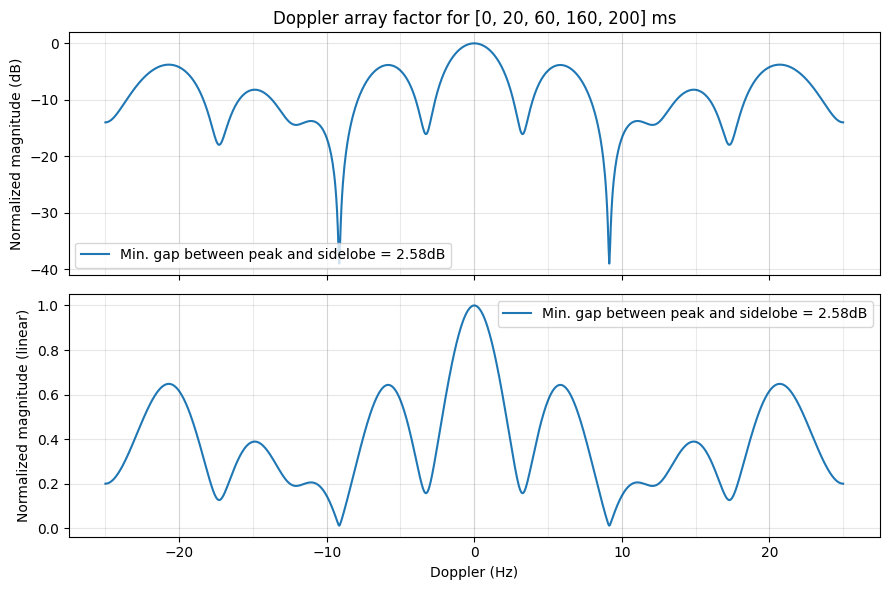

In [103]:
import numpy as np
import matplotlib.pyplot as plt

# Symbol time offsets in seconds (same as sym_delays in your code)
srs_period = 20e-3
dmrs_period = 2.5e-3
t_i = 1e-3*np.array([0, 20, 60, 160, 200])

# Doppler axis: fine grid so the teeth are well resolved
f = np.arange(-25, 25.01, 0.05)   # Hz

# Array factor: |sum_i exp(-j 2 pi f t_i)|, normalized
AF = np.abs(np.exp(-1j * 2 * np.pi * np.outer(f, t_i)).sum(axis=1)) / len(t_i)
AF_dB = 20 * np.log10(np.maximum(AF, 1e-6))

# # Same thing using only the three clustered symbols (no 200 ms symbol)
# AF_cl = np.abs(np.exp(-1j * 2 * np.pi * np.outer(f, t_i[:3])).sum(axis=1)) / 3
# AF_cl_dB = 20 * np.log10(np.maximum(AF_cl, 1e-6))

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax[0].plot(f, AF_dB, label="Min. gap between peak and sidelobe = 2.58dB")
# ax[0].plot(f, AF_cl_dB, "--", label="3 clustered symbols only")
ax[0].set_ylabel("Normalized magnitude (dB)")
# ax[0].set_ylim(-20, 1)
ax[0].grid(True, alpha=0.3)
ax[0].legend()
ax[0].set_title("Doppler array factor for [0, 20, 60, 160, 200] ms")

ax[1].plot(f, AF, label="Min. gap between peak and sidelobe = 2.58dB")
# ax[1].plot(f, AF_cl, "--", label="3 clustered symbols only")
ax[1].set_xlabel("Doppler (Hz)")
ax[1].set_ylabel("Normalized magnitude (linear)")
ax[1].grid(True, alpha=0.3)
ax[1].legend()

# Mark where a 5 Hz comb would sit
for a in ax:
    for fk in np.arange(-25, 26, 5):
        a.axvline(fk, color="k", alpha=0.08, lw=0.8)

plt.tight_layout()
plt.show()


In [100]:
import numpy as np

def sidelobe_db(t_ms, fmax=25, main_excl=1.5):
    t = np.array(t_ms) * 1e-3
    f = np.arange(-fmax, fmax + 0.01, 0.05)
    af = np.abs(np.exp(-1j*2*np.pi*np.outer(f, t)).sum(axis=1)) / len(t)
    return 20*np.log10(af[np.abs(f) > main_excl].max())

for s in ([0, 20, 80, 200],
          [0, 5, 20, 80, 200],
          [0, 2.5, 10, 40, 200],
          [0, 20, 60, 160, 200]):
    print(s, f"{sidelobe_db(s):.2f} dB")

[0, 20, 80, 200] -2.45 dB
[0, 5, 20, 80, 200] -2.20 dB
[0, 2.5, 10, 40, 200] -0.96 dB
[0, 20, 60, 160, 200] -2.58 dB


Peak 1: Doppler = 0 Hz, delay = 15 samples (0.061 us), level = 0.0 dB
Peak 2: Doppler = 15 Hz, delay = 31 samples (0.126 us), level = -1.4 dB


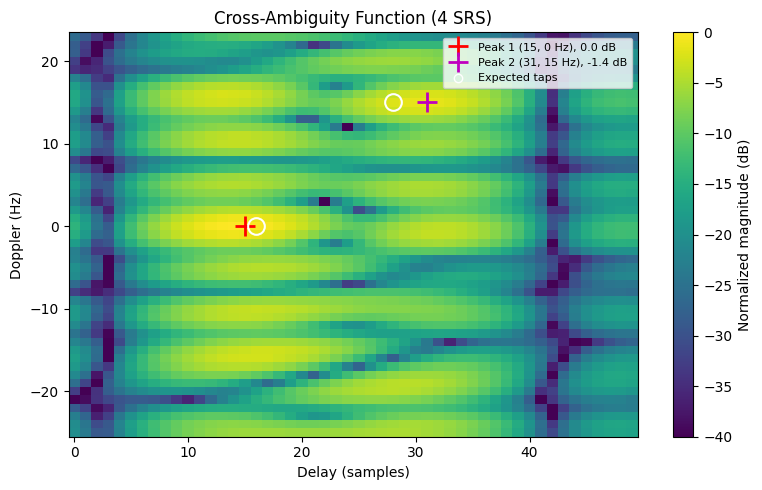

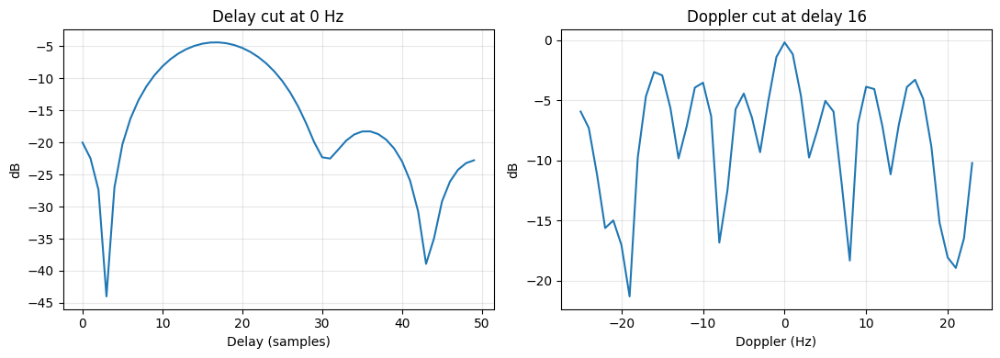

In [54]:
from scipy.ndimage import maximum_filter

f_search = np.arange(-25, 24, 1)
t_search = np.arange(0, 50, 1)

caf = np.zeros([len(f_search), len(t_search)])

for iter0 in range(0, 1):
    for t in range(0, len(t_search)):
        for f in range(0, len(f_search)):
            est_mean_time0 = np.concatenate([complex_time0[iter0, 0, :], complex_time0[iter0, 1, :], complex_time0[iter0, 2, :], complex_time0[iter0, 3, :]])
            shifted_sig = np.concatenate([np.roll(np.conj(time_gensym[0, :]), t_search[t])*est_mean_time0[0:osf*N_ifft], \
                                        np.roll(np.conj(time_gensym[1, :]), t_search[t])*est_mean_time0[osf*N_ifft:2*osf*N_ifft], \
                                        np.roll(np.conj(time_gensym[2, :]), t_search[t])*est_mean_time0[2*osf*N_ifft:3*osf*N_ifft], \
                                        np.roll(np.conj(time_gensym[3, :]), t_search[t])*est_mean_time0[3*osf*N_ifft:4*osf*N_ifft]])
            
            caf[f, t] = np.abs(np.sum(np.concatenate([shifted_sig[0:osf*N_ifft], \
                                                    np.exp(-1j*2*np.pi*f_search[f]*sym_delays[1])*shifted_sig[osf*N_ifft:2*osf*N_ifft], \
                                                    np.exp(-1j*2*np.pi*f_search[f]*sym_delays[2])*shifted_sig[2*osf*N_ifft:3*osf*N_ifft], \
                                                    np.exp(-1j*2*np.pi*f_search[f]*sym_delays[3])*shifted_sig[3*osf*N_ifft:4*osf*N_ifft]])))
            
# Normalize, then convert to dB
caf_norm = caf / np.max(caf)
caf_db = 20*np.log10(caf_norm + 1e-12)

# --- Find the 2 strongest local peaks ---
n_peaks = 2
nbhd = (5, 5)   # (Doppler bins, delay bins) exclusion window around each peak
local_max = (caf == maximum_filter(caf, size=nbhd, mode='constant'))
cand_f, cand_t = np.nonzero(local_max)
order = np.argsort(caf[cand_f, cand_t])[::-1][:n_peaks]
peaks = [(f_search[cand_f[i]], t_search[cand_t[i]], caf_db[cand_f[i], cand_t[i]]) for i in order]

for k, (fp, tp, lvl) in enumerate(peaks):
    print(f"Peak {k+1}: Doppler = {fp} Hz, delay = {tp} samples "
          f"({tp/(osf*f_s)*1e6:.3f} us), level = {lvl:.1f} dB")

# Expected (ground-truth) taps: (delay, Doppler)
truth = [(16, 0), (28, 15)]

# --- 2-D CAF heatmap ---
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolormesh(t_search, f_search, caf_db, shading='auto',
                   cmap='viridis', vmin=-40, vmax=0)
markers = ['r+', 'm+']
for k, (fp, tp, lvl) in enumerate(peaks):
    ax.plot(tp, fp, markers[k], ms=14, mew=2,
            label=f'Peak {k+1} ({tp}, {fp} Hz), {lvl:.1f} dB')
for (tt, ft) in truth:
    ax.plot(tt, ft, 'wo', ms=12, mfc='none', mew=1.5)
ax.plot([], [], 'wo', mfc='none', label='Expected taps')
ax.set_xlabel('Delay (samples)')
ax.set_ylabel('Doppler (Hz)')
ax.set_title('Cross-Ambiguity Function (4 SRS)')
fig.colorbar(im, ax=ax, label='Normalized magnitude (dB)')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()


# --- Cuts through the peak ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(t_search, caf_db[f_idx, :])
ax1.set_xlabel('Delay (samples)'); ax1.set_ylabel('dB')
ax1.set_title(f'Delay cut at {f_peak} Hz'); ax1.grid(True, alpha=0.3)

ax2.plot(f_search, caf_db[:, t_idx])
ax2.set_xlabel('Doppler (Hz)'); ax2.set_ylabel('dB')
ax2.set_title(f'Doppler cut at delay {t_peak}'); ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
np.random.seed(10)

K = 1
N_SYM = 5
sym_delays = np.array([0, srs_period, 3*srs_period, 8*srs_period, 10*srs_period])
# nPRB_dmrs = 12

tau_space = np.arange(4, 100, 4)
theta_space = np.arange(-75, 75, 5)*np.pi/180
Doppler_space = np.array([15])

rmse_tau = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_Doppler = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
detection = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):
        for iter4 in range(0, len(Doppler_space)):

            print("Starting {}th AoA, {}th ToA and {}th Doppler \n".format(iter3, iter2, iter4))

            err_Doppler = np.zeros([K])
            err_theta = np.zeros([K])
            err_tau = np.zeros([K])
            detect = np.zeros([K])
            est_Doppler = np.zeros([K])
            est_theta = np.zeros([K])
            est_tau = np.zeros([K])

            obj_theta = theta_space[iter3]*np.ones(K)
            obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
            obj_Doppler = Doppler_space[iter4]*np.ones(K)
            obj_pathgain = 10000*np.ones(K)

            gen_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_sig_freq = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Frequency domain representation of the received signal
            H_combed = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Estimate the channel using X_pilot as pilot symbols
            H = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Interpolated channel estimates

            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    obj_tau_temp = obj_tau[k] - Doppler_space[iter4]*sym_delays[n_sym]/f_c
                    obj_phase = -f_c*obj_tau_temp

                    Xn = np.zeros([12*nPRB], dtype=np.complex128)
 
                    if n_sym == 0 or n_sym == 3 or n_sym == 4 or n_sym == 1 or n_sym == 2:
                        m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
                        Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)
                    # if n_sym == 1 or n_sym == 2:
                    #     m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
                    #     Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
                    
                    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                    Xn = np.reshape(Xn, [N_ifft, 1])

                    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                    
                    # if n_sym == 1 or n_sym == 2:
                    #     X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
                    if n_sym == 0 or n_sym == 3 or n_sym == 4 or n_sym == 1 or n_sym == 2:
                        X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
                    
                    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                    n = np.reshape(n, [N_ifft, 1])
                    n = np.tile(n, [1, N_ifft])

                    # This loop just generates the OFDM samples in time domain
                    temp_xn = np.tile(Xn, [1, N_ifft])
                    phase = -f_c*tau[0, :]

                    for l in range(0, 1):
                        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                            gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                    gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    # Add the AWGN noise to the generated samples
                    rcvd_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


                    ### Channel estimation

                    # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
                    rcvd_sig_freq[k, n_sym, :, :] = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal[k, n_sym, :, :], axis=1)

                    H_combed[k, n_sym, :, :] = rcvd_sig_freq[k, n_sym, :, :]*np.conjugate(np.tile(X_pilot[np.newaxis, :], [N_ant, 1]))
        
            Xn = np.zeros([N_SYM, 12*nPRB], dtype=np.complex128)
            
            for n_sym in range(0, N_SYM):
                # if n_sym == 1 or n_sym == 2:
                #     m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn should occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
                #     Xn[n_sym, np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
                if n_sym == 0 or n_sym == 3 or n_sym == 4 or n_sym == 1 or n_sym == 2:
                    m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
                    Xn[n_sym, np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

                for k in range(0, K):
                    for n_ant in range(0, N_ant):
                        H[k, n_sym, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_sym, n_ant, :], nPRB, N_ifft, K_TC_dmrs)                

            Xn = np.concatenate([Xn[:, 6*nPRB:12*nPRB], np.zeros([N_SYM, N_ifft - 12*nPRB]), Xn[:, 0:6*nPRB]], axis=1)
            
            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H[:, :, 0, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym0[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=2)
            complex_rxsym1 = H[:, :, 1, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym1[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=2)
            complex_rxsym2 = H[:, :, 2, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym2[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=2)
            complex_rxsym3 = H[:, :, 3, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym3[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=2)

            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os = np.concatenate([Xn[:, 0:N_ifft//2], np.zeros([N_SYM, (osf-1)*N_ifft]), Xn[:, N_ifft//2:N_ifft]], axis=1)
            time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os, axis=1)
            time_gensym_serial = np.concatenate([time_gensym[0, :], time_gensym[1, :], time_gensym[2, :], time_gensym[3, :], time_gensym[4, :]])

            for iter0 in range(0, K):
                print("---------------------Start of {}th symbol------------------------".format(iter0))

                est_mean_time0 = np.concatenate([complex_time0[iter0, 0, :], complex_time0[iter0, 1, :], complex_time0[iter0, 2, :], complex_time0[iter0, 3, :], complex_time0[iter0, 4, :]])
                est_mean_time1 = np.concatenate([complex_time1[iter0, 0, :], complex_time1[iter0, 1, :], complex_time1[iter0, 2, :], complex_time1[iter0, 3, :], complex_time1[iter0, 4, :]])
                est_mean_time2 = np.concatenate([complex_time2[iter0, 0, :], complex_time2[iter0, 1, :], complex_time2[iter0, 2, :], complex_time2[iter0, 3, :], complex_time2[iter0, 4, :]])
                est_mean_time3 = np.concatenate([complex_time3[iter0, 0, :], complex_time3[iter0, 1, :], complex_time3[iter0, 2, :], complex_time3[iter0, 3, :], complex_time3[iter0, 4, :]])
        
                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)
                
                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
                parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

                # Search space for the parameters
                f_search = np.arange(-25, 24, 1)
                t_search = np.arange(-50, 100, 1)
                theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
                
                for iter in range(0, resolve):
                
                    beam_strength = np.zeros([len(theta_search), L])
                    caf_freq = np.zeros([len(f_search), L])
                    caf_time = np.zeros([len(t_search), L])
                    
                    for l in range(0, L):
            
                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(time_gensym_serial[np.newaxis, :], [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 4*osf*N_ifft:5*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                            
                            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[4])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig
            
                        if iter > 1:
                            theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                            # f_search = np.arange(-20, 20, 1) + np.real(parameters[1, l])
                            
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))
            
                        # mean_chan = np.average(est_mean_rxsym, axis=1)
            
                        # START - Code for beam sweeping here and finding the strongest direction.
            
                        for i in range(0, len(theta_search)):
                            beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)
            
                            # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                            
                        max_idx = np.argmax(beam_strength[:, l])
                        max_theta = theta_search[max_idx] 
            
                        parameters[0, l] = max_theta
                        # END - Code for beam sweeping here and finding the strongest direction.
            
                        # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)
            
                        n = np.arange(0, osf*N_ifft, 1)
            
                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])*mean_chan_subcarrier, axis=0)
            
                        max_caf = 0
                        for t in range(0, len(t_search)):
                            caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym[0, :]), t_search[t])*combined_chan[0:osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[1, :]), t_search[t])*combined_chan[osf*N_ifft:2*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[2, :]), t_search[t])*combined_chan[2*osf*N_ifft:3*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[3, :]), t_search[t])*combined_chan[3*osf*N_ifft:4*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[4, :]), t_search[t])*combined_chan[4*osf*N_ifft:5*osf*N_ifft]))
                            
                            if caf_time[t,l] > max_caf:
                                t_best = t
                                max_caf = caf_time[t,l]
                            
                        max_caf = 0
                        shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym[0, :]), t_search[t_best])*combined_chan[0:osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[1, :]), t_search[t_best])*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[2, :]), t_search[t_best])*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[3, :]), t_search[t_best])*combined_chan[3*osf*N_ifft:4*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[4, :]), t_search[t_best])*combined_chan[4*osf*N_ifft:5*osf*N_ifft]])
                        for f in range(0, len(f_search)):
                            caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[1])*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[2])*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[3])*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[4])*shifted_combined_chan[4*osf*N_ifft:5*osf*N_ifft]])))
                            if caf_freq[f,l] > max_caf:
                                f_best = f
                                max_caf = caf_freq[f,l]
                        
                        parameters[1, l] = f_search[f_best]
                        parameters[2, l] = t_search[t_best]
            
                        # END - Code for estimating the transmit delay and Doppler using CAF
            
                        # START - Code that is used to regenerate the signal using the estimated parameters
            
                        generated_sig = np.tile(time_gensym_serial[np.newaxis, :], [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                        generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 4*osf*N_ifft:5*osf*N_ifft], t_search[t_best], axis=1)], axis=1)
            
                        generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[4])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                        alpha = np.average(mean_chan_subcarrier/generated_sig)
            
                        parameters[3, l] = alpha
            
                        generated_sig = alpha*generated_sig
            
                        residual_sig = mean_chan_subcarrier - generated_sig
            
                        mean_chan_subcarrier = residual_sig
            
                        # END - Code that is used to regenerate the signal using the estimated parameters

                t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
                theta_est = np.real(parameters[0, :])*180/np.pi
                alpha_est = np.abs(parameters[3, :])
                Doppler_est = np.real(parameters[1, :])
                t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

                err_max = 100
                for l in range(0, len(t_est)):
                    if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                    and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                        
                        err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                        l_obj = l

                print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
                print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
                print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
                print("Estimated ToA for shortlisted paths: ", t_est)

                if (err_max < 100) and len(t_est) > 0:
                    print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                    print(l_ue)
                    print(l_obj)

                    err_theta[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                    err_tau[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                    err_Doppler[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                    detect[iter0] = 1
                    
                    est_Doppler[iter0] = Doppler_est[l_obj]
                    est_theta[iter0] = theta_est[l_obj]
                    est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

            idx = np.where(detect == 1)
            rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
            rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
            rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))
            detection[iter3, iter2, iter4] = len(idx[0])/K*100

Starting 0th AoA, 0th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01  5.78880294e-01]
Estimated ToA for all paths:  [65.10416667 69.17317708 89.51822917]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 69.17317708 89.51822917]
Object is detected for this symbol with -75.00000000000001 AoA, 70.71281482795166 ToA, 15.0 Doppler of the object
0
1
Starting 0th AoA, 1th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [ 5.92249884e-03 -7.50515487e+01 -5.67035296e-01]
Estimated ToA for all paths:  [65.10416667 73.2421875  40.69010417]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [65.10416667 73.2421875 ]
Object is detected for this symbol with -75.00000000000001 AoA, 74.71281482795166 ToA, 15.0 Doppler of the object
0
1
Starting 0th A

In [ ]:
rmse_tau_51 = rmse_tau
rmse_theta_51 = rmse_theta
rmse_Doppler_51 = rmse_Doppler
detection_51 = detection
rmse_srs_51 = np.concatenate([np.reshape(rmse_tau_51, [1, np.shape(rmse_tau_51)[0], np.shape(rmse_tau_51)[1], np.shape(rmse_tau_51)[2]]), \
                               np.reshape(rmse_theta_51, [1, np.shape(rmse_theta_51)[0], np.shape(rmse_theta_51)[1], np.shape(rmse_theta_51)[2]]), \
                               np.reshape(rmse_Doppler_51, [1, np.shape(rmse_Doppler_51)[0], np.shape(rmse_Doppler_51)[1], np.shape(rmse_Doppler_51)[2]]), \
                               np.reshape(detection_51, [1, np.shape(detection_51)[0], np.shape(detection_51)[1], np.shape(detection_51)[2]])], axis=0)
np.save("rmse_5Sym_srs_51_2tapchan.npy", rmse_srs_51)

The below code is used for running comparison tests between SRS and DMRS by generating results for (SRS+DMRS) case for a 2-tap channel (LoS and a Object path).

This comparison is for AoA, ToF and Doppler, so we are using 4 OFDM symbols (2 SRS and 2 DMRS symbols) for estimation. 

Assumption -> All OFDM symbols have the same absolute time offset. We are going to perform parameter estimation using all 4 symbols in tandem. This assumption is only made to not let the time offset correction to affect the comparison between SRS, DMRS and SRS+DMRS.

Process for parameter estimation -
1. Perform AoA, ToF and Doppler estimation for 4 OFDM symbol stitched together (SRS | DMRS (dmrs_period) | DMRS (4 * dmrs_period) | SRS (10 * srs_period))

In [ ]:
np.random.seed(10)

K = 1
N_SYM = 5
sym_delays = np.array([0, 2*dmrs_period, 8*dmrs_period, 4*srs_period, 10*srs_period])
nPRB_dmrs = 12

tau_space = np.arange(4, 100, 4)
theta_space = np.arange(-75, 75, 5)*np.pi/180
Doppler_space = np.array([15])

rmse_tau = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_theta = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
rmse_Doppler = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])
detection = np.zeros([len(theta_space), len(tau_space), len(Doppler_space)])

for iter3 in range(0, len(theta_space)):
    for iter2 in range(0, len(tau_space)):
        for iter4 in range(0, len(Doppler_space)):

            print("Starting {}th AoA, {}th ToA and {}th Doppler \n".format(iter3, iter2, iter4))

            err_Doppler = np.zeros([K])
            err_theta = np.zeros([K])
            err_tau = np.zeros([K])
            detect = np.zeros([K])
            est_Doppler = np.zeros([K])
            est_theta = np.zeros([K])
            est_tau = np.zeros([K])

            obj_theta = theta_space[iter3]*np.ones(K)
            obj_tau = (tau_space[iter2]*1e-9 + tau[0, 0])*np.ones(K)
            obj_Doppler = Doppler_space[iter4]*np.ones(K)
            obj_pathgain = 10000*np.ones(K)

            gen_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Generated signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_signal = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Noisy signal for K scenarios, N_ant antennas and N_ifft samples
            rcvd_sig_freq = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Frequency domain representation of the received signal
            H_combed = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Estimate the channel using X_pilot as pilot symbols
            H = np.zeros([K, N_SYM, N_ant, N_ifft], dtype=np.complex128) # Interpolated channel estimates

            for k in range(0, K):
                for n_sym in range(0, N_SYM):
                    obj_tau_temp = obj_tau[k] - Doppler_space[iter4]*sym_delays[n_sym]/f_c
                    obj_phase = -f_c*obj_tau_temp

                    Xn = np.zeros([12*nPRB], dtype=np.complex128)
 
                    if n_sym == 0 or n_sym == 3 or n_sym == 4:
                        m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
                        Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)
                    if n_sym == 1 or n_sym == 2:
                        m = np.arange(0, int(np.ceil(12*nPRB_dmrs / K_TC_dmrs)), 1)
                        Xn[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS pilot symbols (ZC sequence)
                    
                    Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
                    Xn = np.reshape(Xn, [N_ifft, 1])

                    X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
                    
                    if n_sym == 1 or n_sym == 2:
                        X_pilot[np.arange(0, 12*nPRB_dmrs, K_TC_dmrs)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # DMRS
                    if n_sym == 0 or n_sym == 3 or n_sym == 4:
                        X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS
                    
                    X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

                    t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
                    n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
                    n = np.reshape(n, [N_ifft, 1])
                    n = np.tile(n, [1, N_ifft])

                    # This loop just generates the OFDM samples in time domain
                    temp_xn = np.tile(Xn, [1, N_ifft])
                    phase = -f_c*tau[0, :]

                    for l in range(0, 1):
                        if ((theta[0, l] >= -np.pi/2) and (theta[0, l] < np.pi/2)) and (pathgain[0, l] > 1):
                            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[0, l]) * np.exp(1j*2*np.pi*phase[l]) * \
                                        np.exp(1j*2*np.pi*Doppler[0, l]*t) * \
                                        np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[0, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

                            gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[0, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(obj_pathgain[k]) * np.exp(1j*2*np.pi*obj_phase) * np.exp(1j*2*np.pi*obj_Doppler[k]*t) * \
                                np.sum(temp_xn*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-obj_tau_temp, [1, N_ifft]), [N_ifft, 1])), axis=0)
                    gen_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(obj_theta[k])), [N_ant, 1]), [1, N_ifft]) * \
                                                                np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

                    # Add the AWGN noise to the generated samples
                    rcvd_signal[k, n_sym, :, :] = gen_signal[k, n_sym, :, :] + 1/np.sqrt(2)*(np.random.normal(size=[N_ant, N_ifft]) + 1j*np.random.normal(size=[N_ant, N_ifft]))


                    ### Channel estimation

                    # Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
                    rcvd_sig_freq[k, n_sym, :, :] = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal[k, n_sym, :, :], axis=1)

                    H_combed[k, n_sym, :, :] = rcvd_sig_freq[k, n_sym, :, :]*np.conjugate(np.tile(X_pilot[np.newaxis, :], [N_ant, 1]))
        
            Xn = np.zeros([N_SYM, 12*nPRB], dtype=np.complex128)
            
            for n_sym in range(0, N_SYM):
                if n_sym == 1 or n_sym == 2:
                    m = np.arange(0, 12*nPRB_dmrs, 1) # New and longer set of DMRS symbols (ZC sequence). Xn should occupy the same bandwidth as complex_rxsym so that when we subtract the generated_sig from complex_rxsym, no residual from generated_sig remains.
                    Xn[n_sym, np.arange(0, 12*nPRB_dmrs, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
                if n_sym == 0 or n_sym == 3 or n_sym == 4:
                    m = np.arange(0, 12*nPRB, 1) # New and longer set of SRS symbols (ZC sequence). 
                    Xn[n_sym, np.arange(0, 12*nPRB, 1)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))

                for k in range(0, K):
                    for n_ant in range(0, N_ant):
                        H[k, n_sym, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_sym, n_ant, :], nPRB, N_ifft, K_TC_dmrs)                

            Xn = np.concatenate([Xn[:, 6*nPRB:12*nPRB], np.zeros([N_SYM, N_ifft - 12*nPRB]), Xn[:, 0:6*nPRB]], axis=1)
            
            # First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
            complex_rxsym0 = H[:, :, 0, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym0 = np.concatenate([complex_rxsym0[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym0[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time0 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym0, axis=2)
            complex_rxsym1 = H[:, :, 1, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym1 = np.concatenate([complex_rxsym1[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym1[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time1 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym1, axis=2)
            complex_rxsym2 = H[:, :, 2, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym2 = np.concatenate([complex_rxsym2[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym2[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time2 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym2, axis=2)
            complex_rxsym3 = H[:, :, 3, :]*np.tile(Xn[np.newaxis, :, :], [K, 1, 1])
            complex_rxsym3 = np.concatenate([complex_rxsym3[:, :, 0:N_ifft//2], np.zeros([K, N_SYM, (osf-1)*N_ifft]), complex_rxsym3[:, :, N_ifft//2:N_ifft]], axis=2)
            complex_time3 = np.sqrt(osf*N_ifft)*np.fft.ifft(complex_rxsym3, axis=2)

            # This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
            Xn_os = np.concatenate([Xn[:, 0:N_ifft//2], np.zeros([N_SYM, (osf-1)*N_ifft]), Xn[:, N_ifft//2:N_ifft]], axis=1)
            time_gensym = np.sqrt(osf*N_ifft)*np.fft.ifft(Xn_os, axis=1)
            time_gensym_serial = np.concatenate([time_gensym[0, :], time_gensym[1, :], time_gensym[2, :], time_gensym[3, :], time_gensym[4, :]])

            for iter0 in range(0, K):
                print("---------------------Start of {}th symbol------------------------".format(iter0))

                est_mean_time0 = np.concatenate([complex_time0[iter0, 0, :], complex_time0[iter0, 1, :], complex_time0[iter0, 2, :], complex_time0[iter0, 3, :], complex_time0[iter0, 4, :]])
                est_mean_time1 = np.concatenate([complex_time1[iter0, 0, :], complex_time1[iter0, 1, :], complex_time1[iter0, 2, :], complex_time1[iter0, 3, :], complex_time1[iter0, 4, :]])
                est_mean_time2 = np.concatenate([complex_time2[iter0, 0, :], complex_time2[iter0, 1, :], complex_time2[iter0, 2, :], complex_time2[iter0, 3, :], complex_time2[iter0, 4, :]])
                est_mean_time3 = np.concatenate([complex_time3[iter0, 0, :], complex_time3[iter0, 1, :], complex_time3[iter0, 2, :], complex_time3[iter0, 3, :], complex_time3[iter0, 4, :]])
        
                mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)
                
                resolve = 3 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
                L = 3 # No. of paths estimated
                parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

                # Search space for the parameters
                f_search = np.arange(-25, 24, 1)
                t_search = np.arange(-50, 100, 1)
                theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)
                
                for iter in range(0, resolve):
                
                    beam_strength = np.zeros([len(theta_search), L])
                    caf_freq = np.zeros([len(f_search), L])
                    caf_time = np.zeros([len(t_search), L])
                    
                    for l in range(0, L):
            
                        # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
                        if iter > 0:
                            generated_sig = np.tile(time_gensym_serial[np.newaxis, :], [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                            generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], int(np.real(parameters[2, l])), axis=1), \
                                                            np.roll(generated_sig[:, 4*osf*N_ifft:5*osf*N_ifft], int(np.real(parameters[2, l])), axis=1)], axis=1)
                            
                            generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                            np.exp(1j*2*np.pi*np.real(parameters[1, l])*sym_delays[4])*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                            generated_sig = parameters[3, l]*generated_sig
                            mean_chan_subcarrier = generated_sig + residual_sig
            
                        if iter > 1:
                            theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                            # f_search = np.arange(-20, 20, 1) + np.real(parameters[1, l])
                            
                        est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))
            
                        # mean_chan = np.average(est_mean_rxsym, axis=1)
            
                        # START - Code for beam sweeping here and finding the strongest direction.
            
                        for i in range(0, len(theta_search)):
                            beam_strength[i, l] = np.sum(np.abs(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i])), [1, N_ant]) @ est_mean_rxsym)**2)
            
                            # np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                            
                        max_idx = np.argmax(beam_strength[:, l])
                        max_theta = theta_search[max_idx] 
            
                        parameters[0, l] = max_theta
                        # END - Code for beam sweeping here and finding the strongest direction.
            
                        # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)
            
                        n = np.arange(0, osf*N_ifft, 1)
            
                        combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])*mean_chan_subcarrier, axis=0)
            
                        max_caf = 0
                        for t in range(0, len(t_search)):
                            caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym[0, :]), t_search[t])*combined_chan[0:osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[1, :]), t_search[t])*combined_chan[osf*N_ifft:2*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[2, :]), t_search[t])*combined_chan[2*osf*N_ifft:3*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[3, :]), t_search[t])*combined_chan[3*osf*N_ifft:4*osf*N_ifft])) + \
                                                np.abs(np.sum(np.roll(np.conj(time_gensym[4, :]), t_search[t])*combined_chan[4*osf*N_ifft:5*osf*N_ifft]))
                            
                            if caf_time[t,l] > max_caf:
                                t_best = t
                                max_caf = caf_time[t,l]
                            
                        max_caf = 0
                        shifted_combined_chan = np.concatenate([np.roll(np.conj(time_gensym[0, :]), t_search[t_best])*combined_chan[0:osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[1, :]), t_search[t_best])*combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[2, :]), t_search[t_best])*combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[3, :]), t_search[t_best])*combined_chan[3*osf*N_ifft:4*osf*N_ifft], \
                                                                np.roll(np.conj(time_gensym[4, :]), t_search[t_best])*combined_chan[4*osf*N_ifft:5*osf*N_ifft]])
                        for f in range(0, len(f_search)):
                            caf_freq[f, l] = np.abs(np.sum(np.concatenate([shifted_combined_chan[0:osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[1])*shifted_combined_chan[osf*N_ifft:2*osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[2])*shifted_combined_chan[2*osf*N_ifft:3*osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[3])*shifted_combined_chan[3*osf*N_ifft:4*osf*N_ifft], \
                                                                            np.exp(-1j*2*np.pi*f_search[f]*sym_delays[4])*shifted_combined_chan[4*osf*N_ifft:5*osf*N_ifft]])))
                            if caf_freq[f,l] > max_caf:
                                f_best = f
                                max_caf = caf_freq[f,l]
                        
                        parameters[1, l] = f_search[f_best]
                        parameters[2, l] = t_search[t_best]
            
                        # END - Code for estimating the transmit delay and Doppler using CAF
            
                        # START - Code that is used to regenerate the signal using the estimated parameters
            
                        generated_sig = np.tile(time_gensym_serial[np.newaxis, :], [N_ant, 1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, N_SYM*osf*N_ifft])
            
                        generated_sig = np.concatenate([np.roll(generated_sig[:, 0:osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, osf*N_ifft:2*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 2*osf*N_ifft:3*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 3*osf*N_ifft:4*osf*N_ifft], t_search[t_best], axis=1), \
                                                        np.roll(generated_sig[:, 4*osf*N_ifft:5*osf*N_ifft], t_search[t_best], axis=1)], axis=1)
            
                        generated_sig = generated_sig*np.concatenate([np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[1])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[2])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[3])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1]), \
                                                        np.exp(1j*2*np.pi*f_search[f_best]*sym_delays[4])*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])], axis=1)
            
                        alpha = np.average(mean_chan_subcarrier/generated_sig)
            
                        parameters[3, l] = alpha
            
                        generated_sig = alpha*generated_sig
            
                        residual_sig = mean_chan_subcarrier - generated_sig
            
                        mean_chan_subcarrier = residual_sig
            
                        # END - Code that is used to regenerate the signal using the estimated parameters

                t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
                theta_est = np.real(parameters[0, :])*180/np.pi
                alpha_est = np.abs(parameters[3, :])
                Doppler_est = np.real(parameters[1, :])
                t_est, theta_est, alpha_est, Doppler_est, l_ue = find_los(t_est, theta_est, alpha_est, Doppler_est, AoA_UE[iter_traj])

                err_max = 100
                for l in range(0, len(t_est)):
                    if (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < 15) and (np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0]) < err_max) \
                    and (np.abs(t_est[l] - 1e9*obj_tau[iter0]) < 50) and (l != l_ue):
                        
                        err_max = np.abs(theta_est[l] - 180/np.pi*obj_theta[iter0])
                        l_obj = l

                print("Estimated AoA for all paths: ", np.real(parameters[0, :])*180/np.pi)
                print("Estimated ToA for all paths: ", np.real(parameters[2, :])/(osf*f_s)*1e9)
                print("Estimated Doppler for all paths: ", np.real(parameters[1, :]))
                print("Estimated ToA for shortlisted paths: ", t_est)

                if (err_max < 100) and len(t_est) > 0:
                    print("Object is detected for this symbol with {} AoA, {} ToA, {} Doppler of the object".format(obj_theta[iter0]*180/np.pi, obj_tau[iter0]*1e9, obj_Doppler[iter0]))

                    print(l_ue)
                    print(l_obj)

                    err_theta[iter0] = np.abs(theta_est[l_obj] - 180/np.pi*obj_theta[iter0])
                    err_tau[iter0] = np.abs(t_est[l_obj] - 1e9*obj_tau[iter0])
                    err_Doppler[iter0] = np.abs(Doppler_est[l_obj] - obj_Doppler[iter0])
                    detect[iter0] = 1
                    
                    est_Doppler[iter0] = Doppler_est[l_obj]
                    est_theta[iter0] = theta_est[l_obj]
                    est_tau[iter0] = t_est[l_obj] - t_est[l_ue]

            idx = np.where(detect == 1)
            rmse_tau[iter3, iter2, iter4] = np.sqrt(np.sum(err_tau[idx[0]]**2)/len(idx[0]))
            rmse_theta[iter3, iter2, iter4] = np.sqrt(np.sum(err_theta[idx[0]]**2)/len(idx[0]))
            rmse_Doppler[iter3, iter2, iter4] = np.sqrt(np.sum(err_Doppler[idx[0]]**2)/len(idx[0]))
            detection[iter3, iter2, iter4] = len(idx[0])/K*100

Starting 0th AoA, 0th ToA and 0th Doppler 

---------------------Start of 0th symbol------------------------
Estimated AoA for all paths:  [0.0059225 0.0059225 0.0059225]
Estimated ToA for all paths:  [ 61.03515625 113.93229167  32.55208333]
Estimated Doppler for all paths:  [ 0. 15.  0.]
Estimated ToA for shortlisted paths:  [ 61.03515625 113.93229167]
Object is detected for this symbol with 0.0 AoA, 114.71281482795166 ToA, 15.0 Doppler of the object
0
1


In [ ]:
rmse_tau_51 = rmse_tau
rmse_theta_51 = rmse_theta
rmse_Doppler_51 = rmse_Doppler
detection_51 = detection
rmse_srs_51 = np.concatenate([np.reshape(rmse_tau_51, [1, np.shape(rmse_tau_51)[0], np.shape(rmse_tau_51)[1], np.shape(rmse_tau_51)[2]]), \
                               np.reshape(rmse_theta_51, [1, np.shape(rmse_theta_51)[0], np.shape(rmse_theta_51)[1], np.shape(rmse_theta_51)[2]]), \
                               np.reshape(rmse_Doppler_51, [1, np.shape(rmse_Doppler_51)[0], np.shape(rmse_Doppler_51)[1], np.shape(rmse_Doppler_51)[2]]), \
                               np.reshape(detection_51, [1, np.shape(detection_51)[0], np.shape(detection_51)[1], np.shape(detection_51)[2]])], axis=0)
np.save("rmse_5Sym_srs_51_dmrs_12_2tapchan.npy", rmse_srs_51)

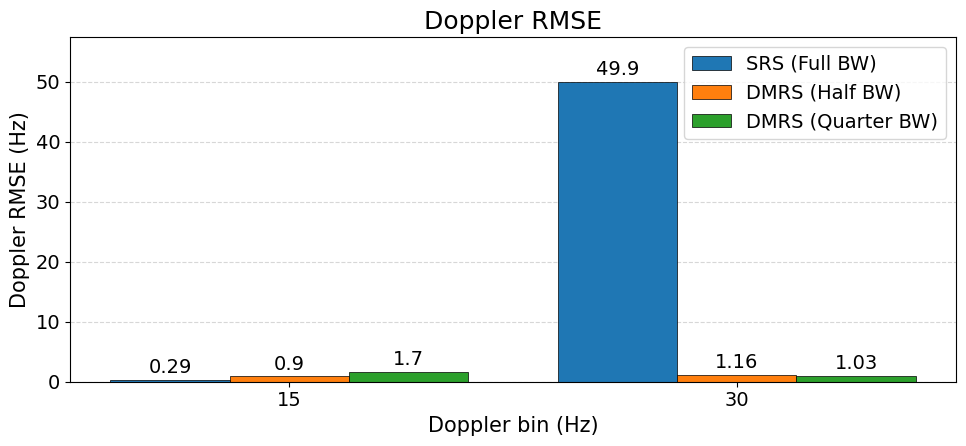

In [35]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 18,         # default text
    "axes.titlesize": 18,    # subplot titles
    "axes.labelsize": 15,    # axis labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})
BAR_LABEL_SIZE = 14        # numbers on top of bars

# x-axis groups: Doppler bins (Hz)
Doppler_bin = [15, 30]

data = {
    "SRS (Full BW)":     {"Doppler": [0.29, 49.9]},
    "DMRS (Half BW)":    {"Doppler": [0.9, 1.16]},
    "DMRS (Quarter BW)": {"Doppler": [1.7, 1.03]},
}

key, ylabel, title = "Doppler", "Doppler RMSE (Hz)", "Doppler RMSE"

colors = {
    "SRS (Full BW)": "tab:blue",
    "DMRS (Half BW)": "tab:orange",
    "DMRS (Quarter BW)": "tab:green",
}

x = np.arange(len(Doppler_bin))
n_series = len(data)
width = 0.8 / n_series

fig, ax = plt.subplots(figsize=(10, 4.8))

for i, (label, values) in enumerate(data.items()):
    offset = (i - (n_series - 1) / 2) * width
    bars = ax.bar(x + offset, values[key], width, label=label,
                  color=colors[label], edgecolor="black", linewidth=0.5)
    ax.bar_label(bars, fmt="%g", fontsize=BAR_LABEL_SIZE, padding=2)

ax.set_xticks(x)
ax.set_xticklabels([str(t) for t in Doppler_bin])
ax.set_xlabel("Doppler bin (Hz)")
ax.set_ylabel(ylabel)
ax.set_title(title)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

# Start at 0 and leave headroom for the bar labels
max_val = max(v for d in data.values() for v in d[key])
ax.set_ylim(0, max_val * 1.15)
ax.legend()

plt.tight_layout()
# plt.savefig("results_bar_plot.png", dpi=200)
plt.show()

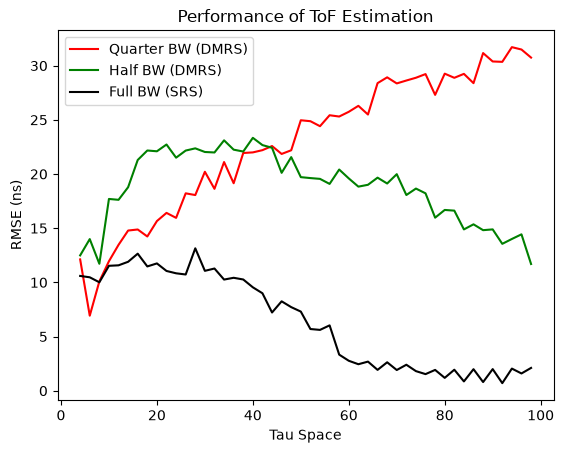

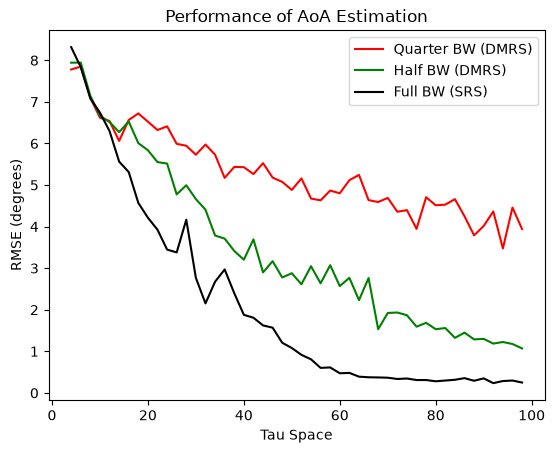

In [12]:
plt.figure(0)
plt.plot(tau_space, rmse_tau_12, label='Quarter BW (DMRS)', color='red')
plt.plot(tau_space, rmse_tau_25, label='Half BW (DMRS)', color='green')
plt.plot(tau_space, rmse_tau, label='Full BW (SRS)', color='black')
plt.xlabel('Tau Space')
plt.ylabel('RMSE (ns)')
plt.title('Performance of ToF Estimation')
plt.legend()

plt.figure(1)
plt.plot(tau_space, rmse_theta_12, label='Quarter BW (DMRS)', color='red')
plt.plot(tau_space, rmse_theta_25, label='Half BW (DMRS)', color='green')
plt.plot(tau_space, rmse_theta, label='Full BW (SRS)', color='black')
plt.xlabel('Tau Space')
plt.ylabel('RMSE (degrees)')
plt.title('Performance of AoA Estimation')

plt.legend()
plt.show()

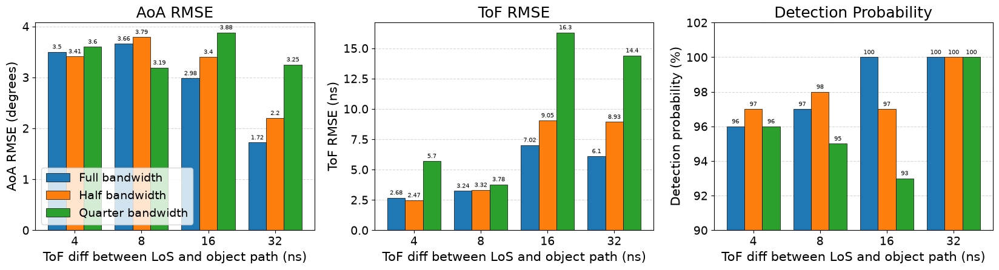

In [168]:
plt.rcParams.update({
    "font.size": 18,         # default text
    "axes.titlesize": 18,    # subplot titles
    "axes.labelsize": 15,    # axis labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})
BAR_LABEL_SIZE = 14        # numbers on top of bars

# x-axis groups: ToF difference between LoS and object path (ns)
tof_diff = [4, 8, 16, 32]
 
data = {
    "Full bandwidth": {
        "aoa": [3.5, 3.66, 2.98, 1.72],
        "tof": [2.68, 3.24, 7.02, 6.1],
        "det": [96, 97, 100, 100],
    },
    "Half bandwidth": {
        "aoa": [3.41, 3.79, 3.4, 2.2],
        "tof": [2.47, 3.32, 9.05, 8.93],
        "det": [97, 98, 97, 100],
    },
    "Quarter bandwidth": {
        "aoa": [3.6, 3.19, 3.88, 3.25],
        "tof": [5.7, 3.78, 16.3, 14.4],
        "det": [96, 95, 93, 100],
    },
}
 
metrics = [
    ("aoa", "AoA RMSE (degrees)", "AoA RMSE"),
    ("tof", "ToF RMSE (ns)", "ToF RMSE"),
    ("det", "Detection probability (%)", "Detection Probability"),
]
 
colors = {
    "Full bandwidth": "tab:blue",
    "Half bandwidth": "tab:orange",
    "Quarter bandwidth": "tab:green",
}
 
x = np.arange(len(tof_diff))
n_series = len(data)
width = 0.8 / n_series
 
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
 
for ax, (key, ylabel, title) in zip(axes, metrics):
    for i, (label, values) in enumerate(data.items()):
        offset = (i - (n_series - 1) / 2) * width
        bars = ax.bar(x + offset, values[key], width, label=label,
                      color=colors[label], edgecolor="black", linewidth=0.5)
        ax.bar_label(bars, fmt="%g", fontsize=7, padding=2)
 
    ax.set_xticks(x)
    ax.set_xticklabels([str(t) for t in tof_diff])
    ax.set_xlabel("ToF diff between LoS and object path (ns)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    
 
# Zoom in on detection probability (all values are 93-100 %)
axes[2].set_ylim(90, 102)
axes[0].legend()
 
plt.tight_layout()
plt.savefig("results_bar_plot.png", dpi=200)
plt.show()

/tmp/ipykernel_6412/1309954694.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


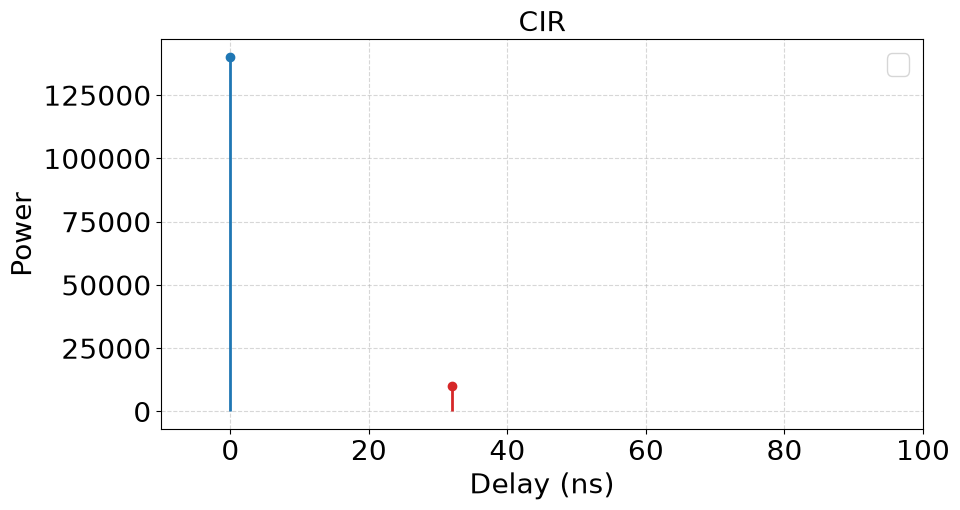

In [178]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 20,
                     "xtick.labelsize": 20, "ytick.labelsize": 20, "legend.fontsize": 20})

# ---- Edit: one (delay_ns, power) tuple per path ----
paths = {
    0:  [(0, 1.4e5)],   # add more paths, e.g. (36, 3e4)
    10: [(32, 1e4)],
}
# ----------------------------------------------------

# colors = {0: "tab:blue", 10: "tab:red"}

fig, ax = plt.subplots(figsize=(10, 5.5))

for t, p in paths.items():
    delays, powers = zip(*p)
    markerline, stemlines, _ = ax.stem(delays, powers, basefmt=" ")
    plt.setp(stemlines, color=colors[t], linewidth=2)
    plt.setp(markerline, color=colors[t])

ax.set_xlabel("Delay (ns)")
ax.set_ylabel("Power")
ax.set_xlim([-10, 100])
ax.set_title("CIR")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

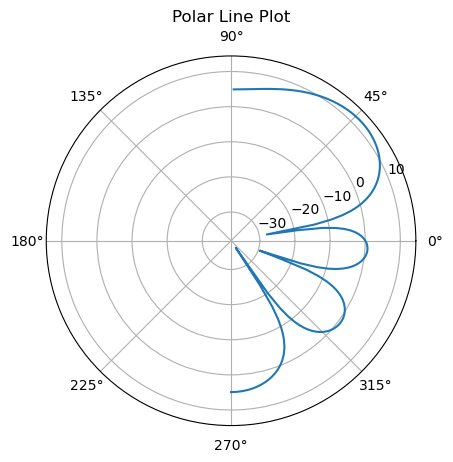

In [ ]:
angle = 42*np.pi/180
d = np.array([0, 0.5, 1, 1.5])
array = np.exp(1j*2*np.pi*d*np.sin(angle))
beam_strength = np.zeros([180])
theta_search = np.arange(-np.pi/2, np.pi/2, 1*np.pi/180)
for i in range(0, len(theta_search)):
    beam_strength[i] = np.abs(np.sum(array*np.exp(-1j*2*np.pi*d*np.sin(theta_search[i]))))**2

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta_search, 10*np.log10(beam_strength))
ax.set_title("Polar Line Plot")
plt.show()

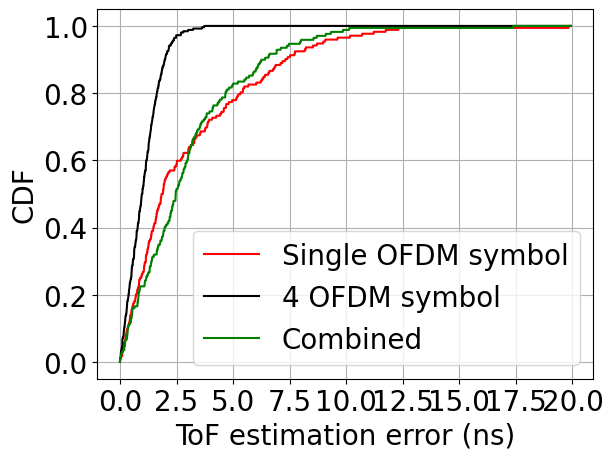

In [30]:
max_val = np.max(np.array([np.max(err_tau), np.max(err_tau_1), np.max(err_tau_4)]))

x = np.arange(0, max_val+0.1, 0.01)
cdf_0 = cal_cdf(err_tau[err_tau != 0], x)

# x = np.arange(0, max_val+0.1, 0.01)
cdf_1 = cal_cdf(err_tau_1[err_tau_1 != 0], x)

# x = np.arange(0, max_val+0.1, 0.01)
cdf_4 = cal_cdf(err_tau_4[err_tau_4 != 0], x)

plt.plot(x, cdf_1, label='Single OFDM symbol', color='red')
plt.plot(x, cdf_4, label='4 OFDM symbol', color='black')
plt.plot(x, cdf_0, label='Combined', color='green')
plt.xlabel('ToF estimation error (ns)', fontsize=20)
plt.ylabel('CDF', fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid()
plt.legend(fontsize=20)